# CS3807 – Deep Learning Laboratory: Experiments 8 and 9
## Effect of Attention Type and Attention Position in Pretrained ResNet50

This notebook follows the assignment protocol: TensorFlow Flowers, 224×224 RGB images, a fixed 70:15:15 split, ImageNet-pretrained ResNet50, Adam, batch size 32, categorical cross-entropy, and identical preprocessing/augmentation across comparisons. Hyperparameter tuning changes **only learning rate and dropout**. All reported scores and plots are computed from this run; no sample result values are hard-coded.

In [4]:
%pip install -q tensorflow-datasets scikit-learn seaborn

In [5]:
%pip install -q importlib_resources tensorflow-datasets

## Setup, reproducibility, dataset split, and sample images

In [6]:
# If needed, run once in a separate cell/environment: %pip install -q tensorflow tensorflow-datasets scikit-learn seaborn pandas matplotlib
import os, re, time, random, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

TensorFlow: 2.21.0
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Split sizes — train: 2569, validation: 550, test: 550


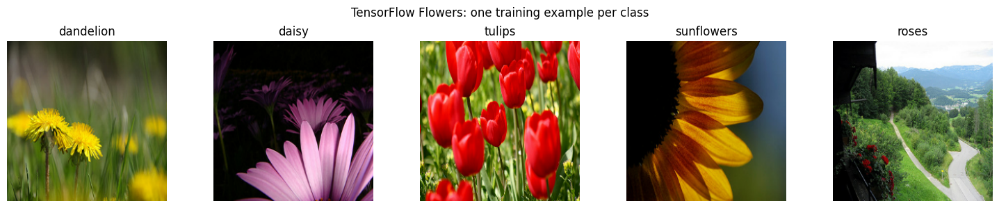

In [7]:
SEED = 42
IMG_SIZE, NUM_CLASSES, BATCH_SIZE = 224, 5, 32
AUTOTUNE = tf.data.AUTOTUNE
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)

(train_raw, val_raw, test_raw), info = tfds.load(
    "tf_flowers",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True, with_info=True
)
CLASS_NAMES = info.features["label"].names
print("Classes:", CLASS_NAMES)
print(f"Split sizes — train: {info.splits['train'].num_examples * .70:.0f}, "
      f"validation: {info.splits['train'].num_examples * .15:.0f}, "
      f"test: {info.splits['train'].num_examples * .15:.0f}")

def resize_image(image, label):
    image = tf.image.resize(tf.cast(image, tf.float32), (IMG_SIZE, IMG_SIZE))
    label = tf.one_hot(tf.cast(label, tf.int32), NUM_CLASSES)
    return image, label

train_data = train_raw.map(resize_image, num_parallel_calls=AUTOTUNE).cache()
val_data = val_raw.map(resize_image, num_parallel_calls=AUTOTUNE).cache()
test_data = test_raw.map(resize_image, num_parallel_calls=AUTOTUNE).cache()

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    tf.keras.layers.RandomRotation(0.05, seed=SEED),
    tf.keras.layers.RandomZoom(0.10, seed=SEED),
    tf.keras.layers.RandomTranslation(0.05, 0.05, seed=SEED),
], name="shared_augmentation")

def make_datasets():
    tr = train_data.shuffle(2048, seed=SEED, reshuffle_each_iteration=True).batch(BATCH_SIZE).prefetch(AUTOTUNE)
    va = val_data.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    te = test_data.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return tr, va, te

train_ds, val_ds, test_ds = make_datasets()

# Show examples from all five classes.
sample_images, sample_labels = [], []
for class_id in range(NUM_CLASSES):
    for image, label in train_data:
        if int(tf.argmax(label).numpy()) == class_id:
            sample_images.append(image.numpy().astype("uint8"))
            sample_labels.append(CLASS_NAMES[class_id])
            break
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 3))
for ax, image, label in zip(axes, sample_images, sample_labels):
    ax.imshow(image); ax.set_title(label); ax.axis("off")
plt.suptitle("TensorFlow Flowers: one training example per class")
plt.tight_layout(); plt.show()

## Shared model components and training/evaluation helpers

In [8]:
# Exact assignment positions: P2=after conv3_x (28×28×512),
# P3=after conv4_x (14×14×1024), P4=after conv5_x (7×7×2048).
POSITION_END = {"P1": "conv2_block3_out", "P2": "conv3_block4_out", "P3": "conv4_block6_out", "P4": "conv5_block3_out"}
POSITION_RESOLUTION = {"P1": "56×56×256", "P2": "28×28×512", "P3": "14×14×1024", "P4": "7×7×2048"}

def channel_attention(x, prefix, reduction=16):
    channels = int(x.shape[-1])
    hidden = max(channels // reduction, 1)
    pooled = tf.keras.layers.GlobalAveragePooling2D(keepdims=True, name=f"{prefix}_gap")(x)
    z = tf.keras.layers.Conv2D(hidden, 1, activation="relu", name=f"{prefix}_reduce")(pooled)
    weights = tf.keras.layers.Conv2D(channels, 1, activation="sigmoid", name=f"{prefix}_weights")(z)
    return tf.keras.layers.Multiply(name=f"{prefix}_refined")([x, weights])

def spatial_attention(x, prefix, kernel=7):
    avg = tf.keras.layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True), name=f"{prefix}_avg")(x)
    mx = tf.keras.layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True), name=f"{prefix}_max")(x)
    pooled = tf.keras.layers.Concatenate(name=f"{prefix}_pool_concat")([avg, mx])
    weights = tf.keras.layers.Conv2D(1, kernel, padding="same", activation="sigmoid",
                                     name=f"{prefix}_weights")(pooled)
    return tf.keras.layers.Multiply(name=f"{prefix}_refined")([x, weights])

def se_attention(x, prefix, reduction=16):
    channels = int(x.shape[-1]); hidden = max(channels // reduction, 1)
    z = tf.keras.layers.GlobalAveragePooling2D(name=f"{prefix}_gap")(x)
    z = tf.keras.layers.Dense(hidden, activation="relu", name=f"{prefix}_reduce")(z)
    z = tf.keras.layers.Dense(channels, activation="sigmoid", name=f"{prefix}_weights_dense")(z)
    z = tf.keras.layers.Reshape((1, 1, channels), name=f"{prefix}_reshape")(z)
    return tf.keras.layers.Multiply(name=f"{prefix}_refined")([x, z])

def eca_attention(x, prefix, kernel=3):
    channels = int(x.shape[-1])
    z = tf.keras.layers.GlobalAveragePooling2D(name=f"{prefix}_gap")(x)
    z = tf.keras.layers.Reshape((channels, 1), name=f"{prefix}_reshape_in")(z)
    z = tf.keras.layers.Conv1D(1, kernel, padding="same", use_bias=False, name=f"{prefix}_conv1d")(z)
    z = tf.keras.layers.Activation("sigmoid", name=f"{prefix}_weights_1d")(z)
    z = tf.keras.layers.Reshape((1, 1, channels), name=f"{prefix}_reshape_out")(z)
    return tf.keras.layers.Multiply(name=f"{prefix}_refined")([x, z])

class SelfAttention2D(tf.keras.layers.Layer):
    def __init__(self, prefix, reduction=4, **kwargs):
        super().__init__(name=prefix, **kwargs)
        self.reduction = reduction
    def build(self, input_shape):
        self.h, self.w, self.c = int(input_shape[1]), int(input_shape[2]), int(input_shape[3])
        hidden = max(self.c // self.reduction, 8)
        self.q = tf.keras.layers.Dense(hidden, use_bias=False, name="query")
        self.k = tf.keras.layers.Dense(hidden, use_bias=False, name="key")
        self.v = tf.keras.layers.Dense(hidden, use_bias=False, name="value")
        self.proj = tf.keras.layers.Dense(self.c, use_bias=False, name="projection")
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)
        super().build(input_shape)
    def call(self, x):
        b = tf.shape(x)[0]; n = self.h * self.w
        flat = tf.reshape(x, (b, n, self.c))
        q, k, v = self.q(flat), self.k(flat), self.v(flat)
        scores = tf.matmul(q, k, transpose_b=True) / tf.sqrt(tf.cast(tf.shape(q)[-1], tf.float32))
        weights = tf.nn.softmax(scores, axis=-1)
        self.last_attention = weights
        y = self.proj(tf.matmul(weights, v))
        y = tf.reshape(y, (b, self.h, self.w, self.c))
        return x + self.gamma * y

def apply_attention(x, kind, position, kernel=7):
    prefix = f"{kind}_{position}".lower()
    if kind == "channel": return channel_attention(x, prefix)
    if kind == "spatial": return spatial_attention(x, prefix, kernel)
    if kind == "channel_spatial":
        return spatial_attention(channel_attention(x, f"channel_{position}".lower()),
                                 f"spatial_{position}".lower(), kernel)
    if kind == "spatial_channel":
        return channel_attention(spatial_attention(x, f"spatial_{position}".lower(), kernel),
                                 f"channel_{position}".lower())
    if kind == "self": return SelfAttention2D(f"self_{position}")(x)
    if kind == "combined_self":
        x = channel_attention(x, f"channel_{position}".lower())
        x = spatial_attention(x, f"spatial_{position}".lower(), kernel)
        return SelfAttention2D(f"self_{position}")(x)
    if kind == "se": return se_attention(x, f"se_{position}".lower())
    if kind == "eca": return eca_attention(x, f"eca_{position}".lower())
    raise ValueError(f"Unknown attention type: {kind}")

def build_model(name, specs=(), dropout_rate=0.3):
    """specs: sequence of (position, attention_type, kernel); empty means baseline."""
    name = re.sub(r"[^A-Za-z0-9_.-]+", "_", name)
    tf.keras.utils.set_random_seed(SEED)
    resnet = tf.keras.applications.ResNet50(weights="imagenet", include_top=False,
                                             input_shape=(IMG_SIZE, IMG_SIZE, 3), name="resnet50")
    # Split the pretrained graph into callable stages so the refined tensor is genuinely
    # passed through the remaining ResNet stages (not merely visualized beside the model).
    stem = tf.keras.Model(resnet.input, resnet.get_layer("pool1_pool").output, name="stem")
    stage2 = tf.keras.Model(resnet.get_layer("pool1_pool").output,
                            resnet.get_layer("conv2_block3_out").output, name="stage2")
    stage3 = tf.keras.Model(resnet.get_layer("conv2_block3_out").output,
                            resnet.get_layer("conv3_block4_out").output, name="stage3")
    stage4 = tf.keras.Model(resnet.get_layer("conv3_block4_out").output,
                            resnet.get_layer("conv4_block6_out").output, name="stage4")
    stage5 = tf.keras.Model(resnet.get_layer("conv4_block6_out").output,
                            resnet.get_layer("conv5_block3_out").output, name="stage5")
    inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = augmentation(inputs)
    x = tf.keras.layers.Lambda(tf.keras.applications.resnet50.preprocess_input, name="resnet_preprocess")(x)
    x = stem(x)
    stages = [("P1", stage2), ("P2", stage3), ("P3", stage4), ("P4", stage5)]
    spec_by_pos = {}
    for pos, kind, kernel in specs:
        spec_by_pos.setdefault(pos, []).append((kind, kernel))
    feature_tensors = {}
    for pos, stage in stages:
        x = stage(x)
        x = tf.keras.layers.Activation("linear", name=f"features_{pos.lower()}")(x)
        feature_tensors[pos] = x
        for kind, kernel in spec_by_pos.get(pos, []):
            x = apply_attention(x, kind, pos, kernel)
            feature_tensors[f"{pos}_{kind}"] = x
    last_features = x
    x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = tf.keras.layers.Dropout(dropout_rate, name="classifier_dropout")(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    model = tf.keras.Model(inputs, outputs, name=name)
    feature_model = tf.keras.Model(inputs, [outputs, last_features], name=f"{name}_features")
    stage_models = [stem, stage2, stage3, stage4, stage5]
    return model, feature_model, stage_models

def train_two_stage(model, stage_models, learning_rate, head_epochs=7, fine_tune_epochs=3, verbose=1):
    # Stage 1: freeze pretrained stages; train inserted attention + classifier.
    for stage in stage_models: stage.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=head_epochs, verbose=verbose)
    # Stage 2: unfreeze only the final ResNet stage; keep BatchNorm layers frozen.
    final_stage = stage_models[-1]
    final_stage.trainable = True
    for layer in final_stage.layers:
        layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=fine_tune_epochs, verbose=verbose)
    history = {}
    for key in set(h1.history) | set(h2.history):
        history[key] = list(h1.history.get(key, [])) + list(h2.history.get(key, []))
    return history

def predict_arrays(model):
    y_true, y_prob = [], []
    for images, labels in test_ds:
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_prob.extend(model.predict(images, verbose=0))
    return np.asarray(y_true), np.asarray(y_prob)

def evaluate_model(name, model):
    y_true, probs = predict_arrays(model)
    y_pred = probs.argmax(axis=1)
    # Warm-up then measure a single image repeatedly to estimate ms/image.
    one = next(iter(test_ds))[0][:1]
    model(one, training=False)
    start = time.perf_counter()
    for _ in range(20): model(one, training=False)
    inference_ms = (time.perf_counter() - start) * 1000 / 20
    return {
        "Model": name, "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Trainable Parameters": int(sum(np.prod(v.shape) for v in model.trainable_variables)),
        "Total Parameters": int(model.count_params()), "Inference Time (ms/image)": inference_ms,
        "y_true": y_true, "y_pred": y_pred
    }

def train_one(name, specs=(), dropout_rate=None, learning_rate=None, head_epochs=7, fine_tune_epochs=3):
    if dropout_rate is None: dropout_rate = BEST_DROPOUT
    if learning_rate is None: learning_rate = BEST_LR
    model, feature_model, stages = build_model(name, specs, dropout_rate)
    history = train_two_stage(model, stages, learning_rate, head_epochs, fine_tune_epochs)
    return {"model": model, "feature_model": feature_model, "stages": stages,
            "history": history, "specs": list(specs), "dropout": dropout_rate, "lr": learning_rate}

## Hyperparameter tuning — learning rate and dropout only


Learning rate=0.001, Dropout=0.3
Best validation accuracy: 0.9220

Learning rate=0.001, Dropout=0.4
Best validation accuracy: 0.9220

Learning rate=0.001, Dropout=0.5
Best validation accuracy: 0.9256

Learning rate=0.0005, Dropout=0.3
Best validation accuracy: 0.9147

Learning rate=0.0005, Dropout=0.4
Best validation accuracy: 0.9129

Learning rate=0.0005, Dropout=0.5
Best validation accuracy: 0.9147

Learning rate=0.0001, Dropout=0.3
Best validation accuracy: 0.9020

Learning rate=0.0001, Dropout=0.4
Best validation accuracy: 0.9111

Learning rate=0.0001, Dropout=0.5
Best validation accuracy: 0.9038


,Learning Rate,Dropout,Best Validation Accuracy,Best Validation Loss
0,0.0010,0.5,0.925590,0.236776
1,0.0010,0.3,0.921960,0.241687
2,0.0010,0.4,0.921960,0.261850
3,0.0005,0.3,0.914701,0.242419
4,0.0005,0.5,0.914701,0.253121
5,0.0005,0.4,0.912886,0.263975
6,0.0001,0.4,0.911071,0.263063
7,0.0001,0.5,0.903811,0.283346
8,0.0001,0.3,0.901996,0.274212



Selected learning rate: 0.001, dropout: 0.5


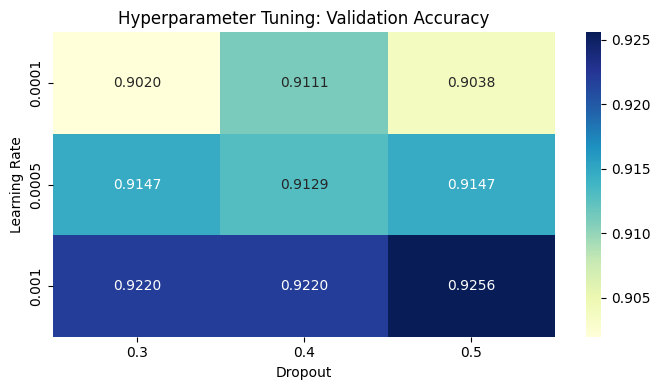

In [9]:
# Hyperparameter tuning: learning rate and dropout only
LEARNING_RATES = [1e-3, 5e-4, 1e-4]
DROPOUT_RATES = [0.3, 0.4, 0.5]

TUNING_HEAD_EPOCHS = 3
TUNING_FINE_TUNE_EPOCHS = 2

tuning_results = []

for lr, drop in itertools.product(LEARNING_RATES, DROPOUT_RATES):

    print(f"\nLearning rate={lr}, Dropout={drop}")

    model, _, stages = build_model(
        f"tuning_lr{lr}_drop{drop}".replace(".", "_"),
        specs=[],
        dropout_rate=drop
    )

    history = train_two_stage(
        model,
        stages,
        learning_rate=lr,
        head_epochs=TUNING_HEAD_EPOCHS,
        fine_tune_epochs=TUNING_FINE_TUNE_EPOCHS,
        verbose=0
    )

    best_val_accuracy = max(history["val_accuracy"])
    best_val_loss = min(history["val_loss"])

    print(f"Best validation accuracy: {best_val_accuracy:.4f}")

    tuning_results.append({
        "Learning Rate": lr,
        "Dropout": drop,
        "Best Validation Accuracy": best_val_accuracy,
        "Best Validation Loss": best_val_loss
    })

    del model, stages, history
    tf.keras.backend.clear_session()

# Display results after all combinations finish
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    ["Best Validation Accuracy", "Best Validation Loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(tuning_df)

BEST_LR = float(tuning_df.loc[0, "Learning Rate"])
BEST_DROPOUT = float(tuning_df.loc[0, "Dropout"])

print(
    f"\nSelected learning rate: {BEST_LR:g}, "
    f"dropout: {BEST_DROPOUT}"
)

# Hyperparameter tuning heatmap
pivot = tuning_df.pivot(
    index="Learning Rate",
    columns="Dropout",
    values="Best Validation Accuracy"
)

plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="YlGnBu")
plt.title("Hyperparameter Tuning: Validation Accuracy")
plt.tight_layout()
plt.show()


## Main Experiment 1 — Attention-type ablation at P3

In [10]:
# A0 baseline; A1 channel; A2 spatial; A3 channel→spatial; A4 self-attention;
# A5 combined channel→spatial→self-attention. All use the selected LR/dropout.
experiment1_specs = {
    "A0 Baseline": [],
    "A1 Channel P3": [("P3", "channel", 7)],
    "A2 Spatial P3": [("P3", "spatial", 7)],
    "A3 Channel+Spatial P3": [("P3", "channel_spatial", 7)],
    "A4 Self-Attention P3": [("P3", "self", 7)],
    "A5 Combined Attention P3": [("P3", "combined_self", 7)],
}
experiment1 = {}
for name, specs in experiment1_specs.items():
    print("\\nTraining", name)
    experiment1[name] = train_one(name, specs)

\nTraining A0 Baseline
Epoch 1/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 23s 205ms/step - accuracy: 0.6314 - loss: 1.0109 - val_accuracy: 0.8675 - val_loss: 0.3990
Epoch 2/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 186ms/step - accuracy: 0.8128 - loss: 0.5295 - val_accuracy: 0.8911 - val_loss: 0.3421
Epoch 3/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 184ms/step - accuracy: 0.8490 - loss: 0.4050 - val_accuracy: 0.9002 - val_loss: 0.3123
Epoch 4/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 181ms/step - accuracy: 0.8762 - loss: 0.3591 - val_accuracy: 0.8875 - val_loss: 0.3204
Epoch 5/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 181ms/step - accuracy: 0.8786 - loss: 0.3320 - val_accuracy: 0.9056 - val_loss: 0.2908
Epoch 6/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 180ms/step - accuracy: 0.8867 - loss: 0.3041 - val_accuracy: 0.9165 - val_loss: 0.2893
Epoch 7/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 181ms/step - accuracy: 0.8945 - loss: 0.2855 - val_accuracy: 0.9093 - val_loss: 0.2711
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 247ms/step - accuracy: 0.9097 - loss: 0.

## Main Experiment 2 — Attention-position ablation

In [11]:
# Keep channel→spatial attention fixed; change only insertion position.
experiment2 = {}
for pos in ["P1", "P2", "P3", "P4"]:
    name = f"Channel+Spatial {pos}"
    print("\\nTraining", name, POSITION_RESOLUTION[pos])
    experiment2[name] = train_one(name, [(pos, "channel_spatial", 7)])

\nTraining Channel+Spatial P1 56×56×256
Epoch 1/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 33s 301ms/step - accuracy: 0.3931 - loss: 1.6579 - val_accuracy: 0.6897 - val_loss: 0.8239
Epoch 2/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 24s 291ms/step - accuracy: 0.6882 - loss: 0.8453 - val_accuracy: 0.8076 - val_loss: 0.5612
Epoch 3/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 22s 274ms/step - accuracy: 0.7610 - loss: 0.6645 - val_accuracy: 0.8348 - val_loss: 0.4733
Epoch 4/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 22s 267ms/step - accuracy: 0.7999 - loss: 0.5628 - val_accuracy: 0.8512 - val_loss: 0.4490
Epoch 5/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 22s 276ms/step - accuracy: 0.8206 - loss: 0.4867 - val_accuracy: 0.8675 - val_loss: 0.4016
Epoch 6/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 41s 276ms/step - accuracy: 0.8287 - loss: 0.4513 - val_accuracy: 0.8711 - val_loss: 0.3934
Epoch 7/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 24s 291ms/step - accuracy: 0.8466 - loss: 0.4326 - val_accuracy: 0.8838 - val_loss: 0.3495
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 35s 323ms/step - accuracy: 

## Main Experiment 3 — Multiple attention positions

In [12]:
# Compare P3 only, P4 only, and P3+P4 using the same channel→spatial module.
experiment3_specs = {
    "Multi P3 only": [("P3", "channel_spatial", 7)],
    "Multi P4 only": [("P4", "channel_spatial", 7)],
    "Multi P3+P4": [("P3", "channel_spatial", 7), ("P4", "channel_spatial", 7)],
}
experiment3 = {}
for name, specs in experiment3_specs.items():
    print("\\nTraining", name)
    experiment3[name] = train_one(name, specs)

\nTraining Multi P3 only
Epoch 1/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 229ms/step - accuracy: 0.5247 - loss: 1.1656 - val_accuracy: 0.8276 - val_loss: 0.4673
Epoch 2/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 215ms/step - accuracy: 0.8237 - loss: 0.4786 - val_accuracy: 0.8857 - val_loss: 0.3351
Epoch 3/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 212ms/step - accuracy: 0.8770 - loss: 0.3629 - val_accuracy: 0.8929 - val_loss: 0.3177
Epoch 4/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 205ms/step - accuracy: 0.8902 - loss: 0.3055 - val_accuracy: 0.8911 - val_loss: 0.2934
Epoch 5/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 202ms/step - accuracy: 0.9046 - loss: 0.2773 - val_accuracy: 0.9056 - val_loss: 0.2740
Epoch 6/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 207ms/step - accuracy: 0.9054 - loss: 0.2503 - val_accuracy: 0.8984 - val_loss: 0.2825
Epoch 7/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 208ms/step - accuracy: 0.9155 - loss: 0.2291 - val_accuracy: 0.9074 - val_loss: 0.2846
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 261ms/step - accuracy: 0.9284 - loss: 

## Main Experiment 4 — Attention order

In [13]:
# Same P3 position and kernel; only the order changes.
experiment4 = {}
for name, kind in [("Order Channel→Spatial", "channel_spatial"),
                   ("Order Spatial→Channel", "spatial_channel")]:
    print("\\nTraining", name)
    experiment4[name] = train_one(name, [("P3", kind, 7)])

\nTraining Order Channel→Spatial
Epoch 1/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 225ms/step - accuracy: 0.5173 - loss: 1.1628 - val_accuracy: 0.8258 - val_loss: 0.4643
Epoch 2/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 211ms/step - accuracy: 0.8420 - loss: 0.4593 - val_accuracy: 0.8766 - val_loss: 0.3495
Epoch 3/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 217ms/step - accuracy: 0.8758 - loss: 0.3609 - val_accuracy: 0.8966 - val_loss: 0.3138
Epoch 4/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 205ms/step - accuracy: 0.8918 - loss: 0.3066 - val_accuracy: 0.8984 - val_loss: 0.2953
Epoch 5/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 201ms/step - accuracy: 0.8992 - loss: 0.2859 - val_accuracy: 0.9002 - val_loss: 0.2976
Epoch 6/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 202ms/step - accuracy: 0.9109 - loss: 0.2412 - val_accuracy: 0.8911 - val_loss: 0.3116
Epoch 7/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 209ms/step - accuracy: 0.9198 - loss: 0.2289 - val_accuracy: 0.9074 - val_loss: 0.2676
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 260ms/step - accuracy: 0.9264 

## Main Experiment 5 — Spatial attention kernel size

In [14]:
# Same P3 position and training protocol; compare spatial kernels 3, 5, and 7.
experiment5 = {}
for kernel in [3, 5, 7]:
    name = f"Spatial Kernel {kernel}x{kernel}"
    print("\\nTraining", name)
    experiment5[name] = train_one(name, [("P3", "spatial", kernel)])

\nTraining Spatial Kernel 3x3
Epoch 1/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 224ms/step - accuracy: 0.6466 - loss: 0.9803 - val_accuracy: 0.8457 - val_loss: 0.4231
Epoch 2/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 210ms/step - accuracy: 0.8124 - loss: 0.5124 - val_accuracy: 0.8947 - val_loss: 0.3231
Epoch 3/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 208ms/step - accuracy: 0.8529 - loss: 0.4052 - val_accuracy: 0.9002 - val_loss: 0.2878
Epoch 4/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 198ms/step - accuracy: 0.8727 - loss: 0.3577 - val_accuracy: 0.9165 - val_loss: 0.2808
Epoch 5/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 198ms/step - accuracy: 0.8895 - loss: 0.3173 - val_accuracy: 0.9165 - val_loss: 0.2820
Epoch 6/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 198ms/step - accuracy: 0.8953 - loss: 0.2927 - val_accuracy: 0.9147 - val_loss: 0.2719
Epoch 7/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 209ms/step - accuracy: 0.9042 - loss: 0.2779 - val_accuracy: 0.9056 - val_loss: 0.2889
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 253ms/step - accuracy: 0.9144 - l

## Additional Task — Established attention mechanisms (SE and ECA)

In [ ]:
# SE and ECA are two additional mechanisms, inserted at P3 as recommended.
additional = {}
for name, kind in [("Additional SE P3", "se"), ("Additional ECA P3", "eca")]:
    print("\\nTraining", name)
    additional[name] = train_one(name, [("P3", kind, 7)])

\nTraining Additional SE P3
Epoch 1/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 224ms/step - accuracy: 0.6543 - loss: 0.8943 - val_accuracy: 0.8639 - val_loss: 0.3686
Epoch 2/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 210ms/step - accuracy: 0.8303 - loss: 0.4534 - val_accuracy: 0.8929 - val_loss: 0.3118
Epoch 3/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 205ms/step - accuracy: 0.8610 - loss: 0.3695 - val_accuracy: 0.9111 - val_loss: 0.2580
Epoch 4/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 197ms/step - accuracy: 0.8817 - loss: 0.3203 - val_accuracy: 0.9056 - val_loss: 0.2593
Epoch 5/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 197ms/step - accuracy: 0.9027 - loss: 0.2686 - val_accuracy: 0.9074 - val_loss: 0.2540
Epoch 6/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 201ms/step - accuracy: 0.9035 - loss: 0.2752 - val_accuracy: 0.9074 - val_loss: 0.2579
Epoch 7/7
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 206ms/step - accuracy: 0.9218 - loss: 0.2411 - val_accuracy: 0.8984 - val_loss: 0.2893
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 252ms/step - accuracy: 0.9276 - los

## Quantitative evaluation, required result tables, and performance visualizations

Evaluating: A0 Baseline
Evaluating: A1 Channel P3
Evaluating: A2 Spatial P3
Evaluating: A3 Channel+Spatial P3
Evaluating: A4 Self-Attention P3
Evaluating: A5 Combined Attention P3
Evaluating: Channel+Spatial P1
Evaluating: Channel+Spatial P2
Evaluating: Channel+Spatial P3
Evaluating: Channel+Spatial P4
Evaluating: Multi P3 only
Evaluating: Multi P4 only
Evaluating: Multi P3+P4
Evaluating: Order Channel→Spatial
Evaluating: Order Spatial→Channel
Evaluating: Spatial Kernel 3x3
Evaluating: Spatial Kernel 5x5
Evaluating: Spatial Kernel 7x7
Evaluating: Additional SE P3
Evaluating: Additional ECA P3


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Trainable Parameters,Total Parameters,Inference Time (ms/image)
0,A5 Combined Attention P3,0.9418,0.9439,0.9403,0.9418,16144553,24778793,268.8892
1,Channel+Spatial P4,0.9400,0.9434,0.9395,0.9406,15490280,24124520,265.8617
2,A4 Self-Attention P3,0.9327,0.9390,0.9331,0.9345,16012294,24646534,266.2939
3,Multi P3 only,0.9309,0.9320,0.9326,0.9321,15095976,23730216,262.1531
4,Channel+Spatial P3,0.9273,0.9301,0.9264,0.9280,15095976,23730216,271.3023
5,Spatial Kernel 3x3,0.9255,0.9308,0.9242,0.9262,14963736,23597976,259.2061
6,A1 Channel P3,0.9255,0.9277,0.9253,0.9260,15095877,23730117,257.8973
7,A3 Channel+Spatial P3,0.9236,0.9275,0.9229,0.9247,15095976,23730216,266.2315
8,Additional SE P3,0.9218,0.9231,0.9226,0.9228,15095877,23730117,260.6866
9,Multi P4 only,0.9218,0.9261,0.9209,0.9225,15490280,24124520,267.9585


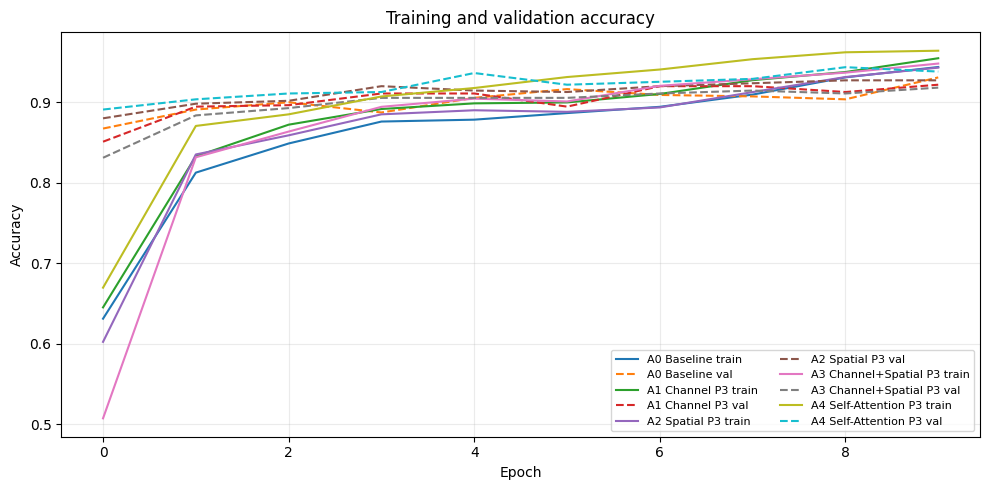

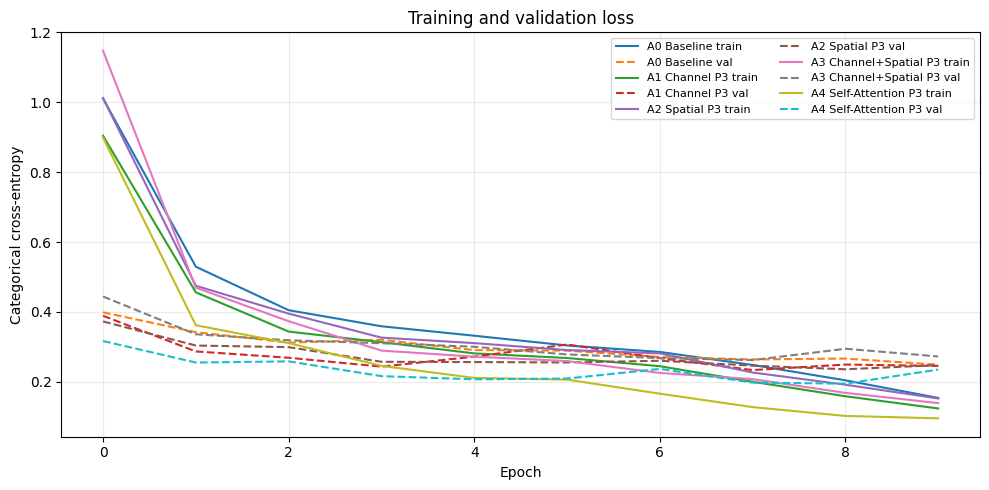

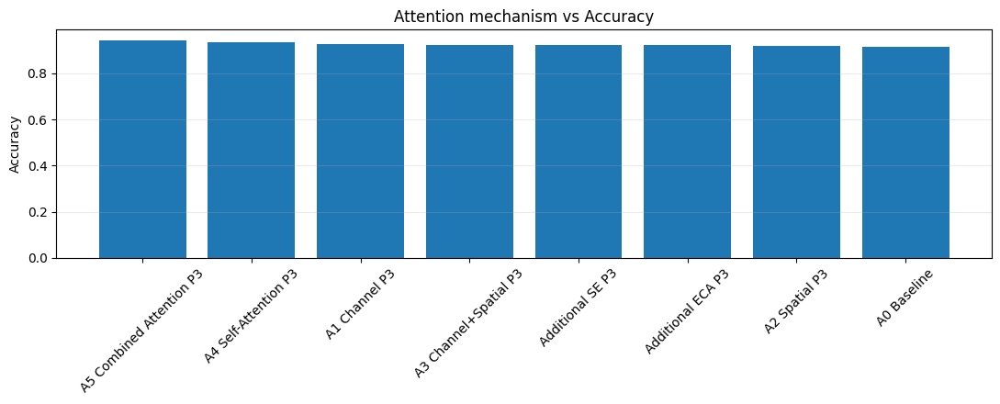

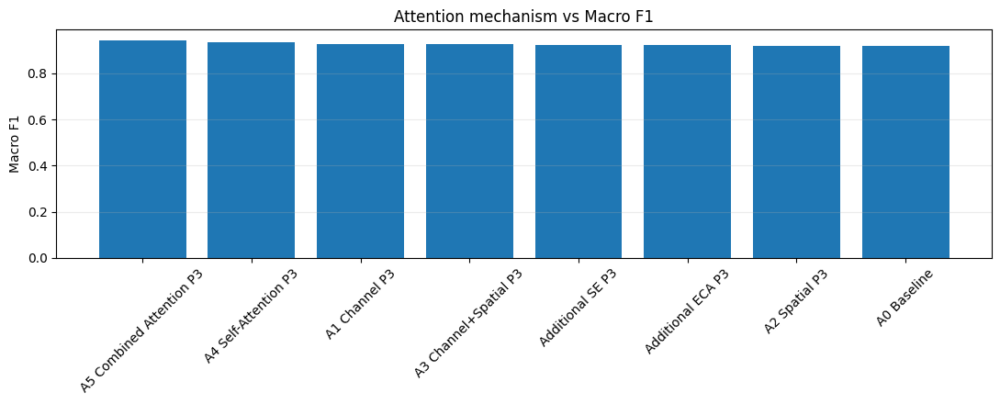

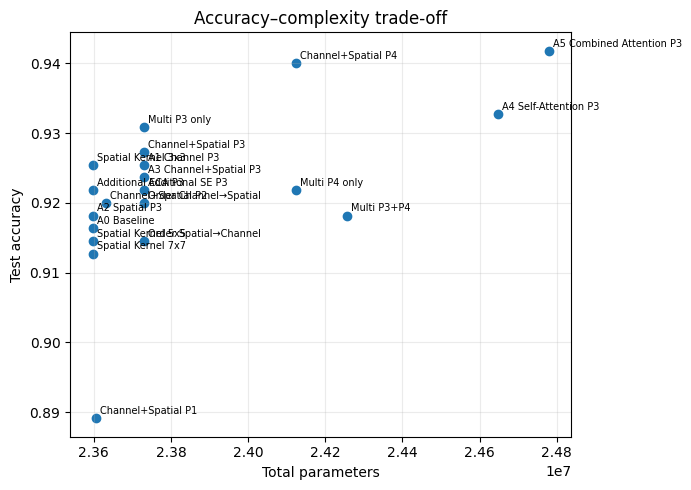

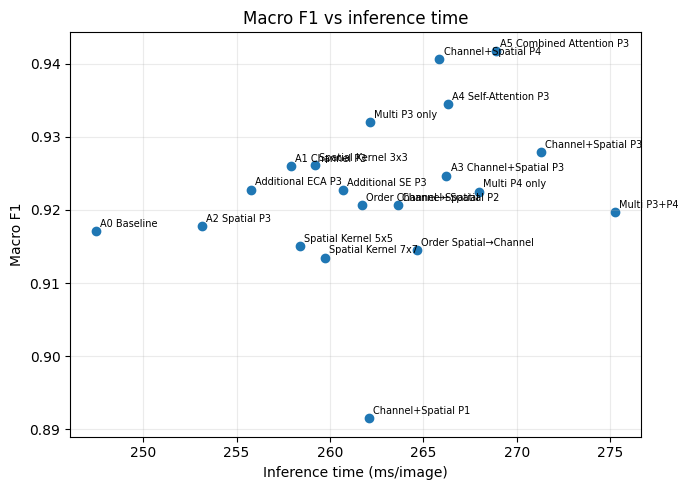

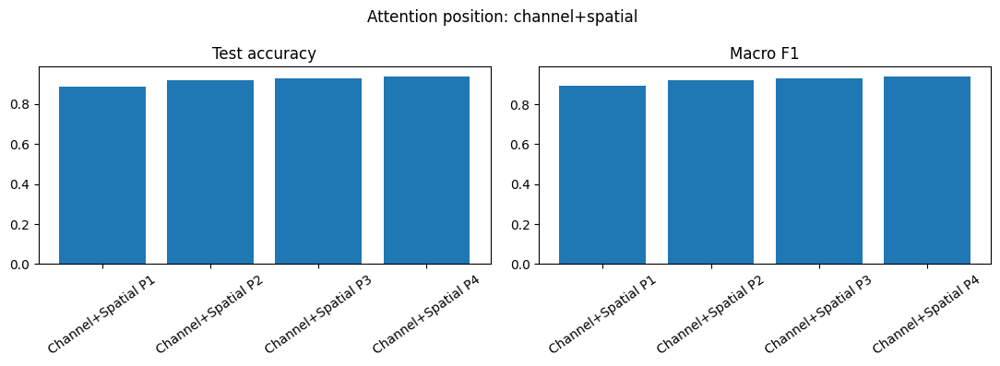

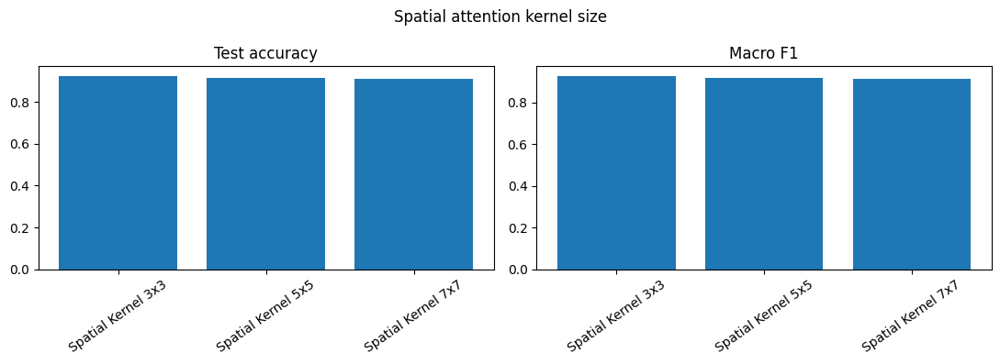

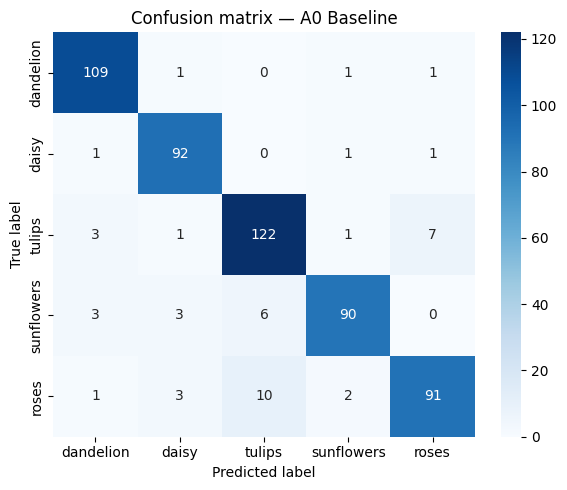

Classification report — A0 Baseline
              precision    recall  f1-score   support

   dandelion       0.93      0.97      0.95       112
       daisy       0.92      0.97      0.94        95
      tulips       0.88      0.91      0.90       134
  sunflowers       0.95      0.88      0.91       102
       roses       0.91      0.85      0.88       107

    accuracy                           0.92       550
   macro avg       0.92      0.92      0.92       550
weighted avg       0.92      0.92      0.92       550



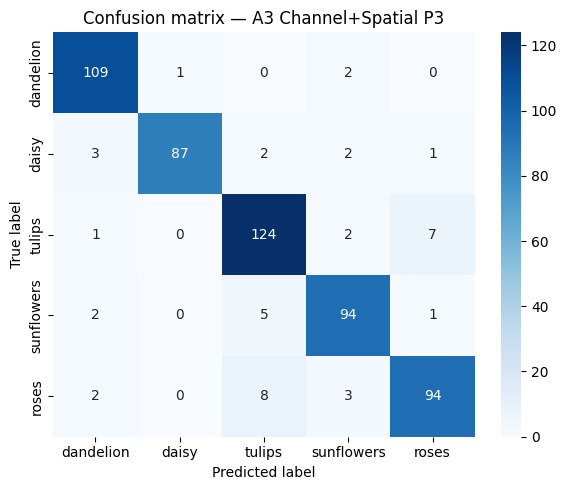

Classification report — A3 Channel+Spatial P3
              precision    recall  f1-score   support

   dandelion       0.93      0.97      0.95       112
       daisy       0.99      0.92      0.95        95
      tulips       0.89      0.93      0.91       134
  sunflowers       0.91      0.92      0.92       102
       roses       0.91      0.88      0.90       107

    accuracy                           0.92       550
   macro avg       0.93      0.92      0.92       550
weighted avg       0.92      0.92      0.92       550



In [16]:
all_runs = {}
for group in [experiment1, experiment2, experiment3, experiment4, experiment5, additional]:
    all_runs.update(group)

result_rows = []
for name, run in all_runs.items():
    print("Evaluating:", name)
    row = evaluate_model(name, run["model"])
    run["evaluation"] = row
    result_rows.append({k: v for k, v in row.items() if k not in ("y_true", "y_pred")})

results_df = pd.DataFrame(result_rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv("attention_experiment_results.csv", index=False)

# Required training/validation accuracy and loss curves for baseline and selected attention models.
selected_histories = {
    name: experiment1[name]["history"]
    for name in ["A0 Baseline", "A1 Channel P3", "A2 Spatial P3", "A3 Channel+Spatial P3", "A4 Self-Attention P3"]
}
fig, ax = plt.subplots(figsize=(10, 5))
for name, hist in selected_histories.items():
    ax.plot(hist["accuracy"], label=f"{name} train")
    ax.plot(hist["val_accuracy"], "--", label=f"{name} val")
ax.set(xlabel="Epoch", ylabel="Accuracy", title="Training and validation accuracy")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for name, hist in selected_histories.items():
    ax.plot(hist["loss"], label=f"{name} train")
    ax.plot(hist["val_loss"], "--", label=f"{name} val")
ax.set(xlabel="Epoch", ylabel="Categorical cross-entropy", title="Training and validation loss")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

# Main mechanism comparisons: accuracy and macro F1.
mechanism_names = ["A0 Baseline", "A1 Channel P3", "A2 Spatial P3", "A3 Channel+Spatial P3",
                   "A4 Self-Attention P3", "A5 Combined Attention P3", "Additional SE P3", "Additional ECA P3"]
mechanism_df = results_df[results_df["Model"].isin(mechanism_names)]
for metric in ["Accuracy", "Macro F1"]:
    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.bar(mechanism_df["Model"], mechanism_df[metric])
    ax.set_ylabel(metric); ax.set_title(f"Attention mechanism vs {metric}")
    ax.tick_params(axis="x", rotation=45); ax.grid(axis="y", alpha=.25)
    plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(results_df["Total Parameters"], results_df["Accuracy"])
for _, row in results_df.iterrows():
    ax.annotate(row["Model"], (row["Total Parameters"], row["Accuracy"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="Total parameters", ylabel="Test accuracy", title="Accuracy–complexity trade-off")
ax.grid(alpha=.25); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(results_df["Inference Time (ms/image)"], results_df["Macro F1"])
for _, row in results_df.iterrows():
    ax.annotate(row["Model"], (row["Inference Time (ms/image)"], row["Macro F1"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="Inference time (ms/image)", ylabel="Macro F1", title="Macro F1 vs inference time")
ax.grid(alpha=.25); plt.tight_layout(); plt.show()

# Experiment 2 and 5 focused plots.
for group, title in [(experiment2, "Attention position: channel+spatial"),
                     (experiment5, "Spatial attention kernel size")]:
    names = list(group.keys())
    sub = results_df.set_index("Model").loc[names].reset_index()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].bar(sub["Model"], sub["Accuracy"]); axes[0].set_title("Test accuracy"); axes[0].tick_params(axis="x", rotation=35)
    axes[1].bar(sub["Model"], sub["Macro F1"]); axes[1].set_title("Macro F1"); axes[1].tick_params(axis="x", rotation=35)
    fig.suptitle(title); plt.tight_layout(); plt.show()

# Assignment-required confusion matrices: baseline and selected attention model.
for name in ["A0 Baseline", "A3 Channel+Spatial P3"]:
    row = all_runs[name]["evaluation"]
    cm = confusion_matrix(row["y_true"], row["y_pred"], labels=range(NUM_CLASSES))
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted label"); plt.ylabel("True label"); plt.title(f"Confusion matrix — {name}")
    plt.tight_layout(); plt.show()
    print(f"Classification report — {name}")
    print(classification_report(row["y_true"], row["y_pred"], labels=range(NUM_CLASSES),
                                target_names=CLASS_NAMES, zero_division=0))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Trainable Parameters,Total Parameters,Inference Time (ms/image)
0,A5 Combined Attention P3,0.9418,0.9439,0.9403,0.9418,16144553,24778793,268.8892
1,Channel+Spatial P4,0.9400,0.9434,0.9395,0.9406,15490280,24124520,265.8617
2,A4 Self-Attention P3,0.9327,0.9390,0.9331,0.9345,16012294,24646534,266.2939
3,Multi P3 only,0.9309,0.9320,0.9326,0.9321,15095976,23730216,262.1531
4,Channel+Spatial P3,0.9273,0.9301,0.9264,0.9280,15095976,23730216,271.3023
5,Spatial Kernel 3x3,0.9255,0.9308,0.9242,0.9262,14963736,23597976,259.2061
6,A1 Channel P3,0.9255,0.9277,0.9253,0.9260,15095877,23730117,257.8973
7,A3 Channel+Spatial P3,0.9236,0.9275,0.9229,0.9247,15095976,23730216,266.2315
8,Additional SE P3,0.9218,0.9231,0.9226,0.9228,15095877,23730117,260.6866
9,Multi P4 only,0.9218,0.9261,0.9209,0.9225,15490280,24124520,267.9585


Results saved to attention_experiment_results.csv


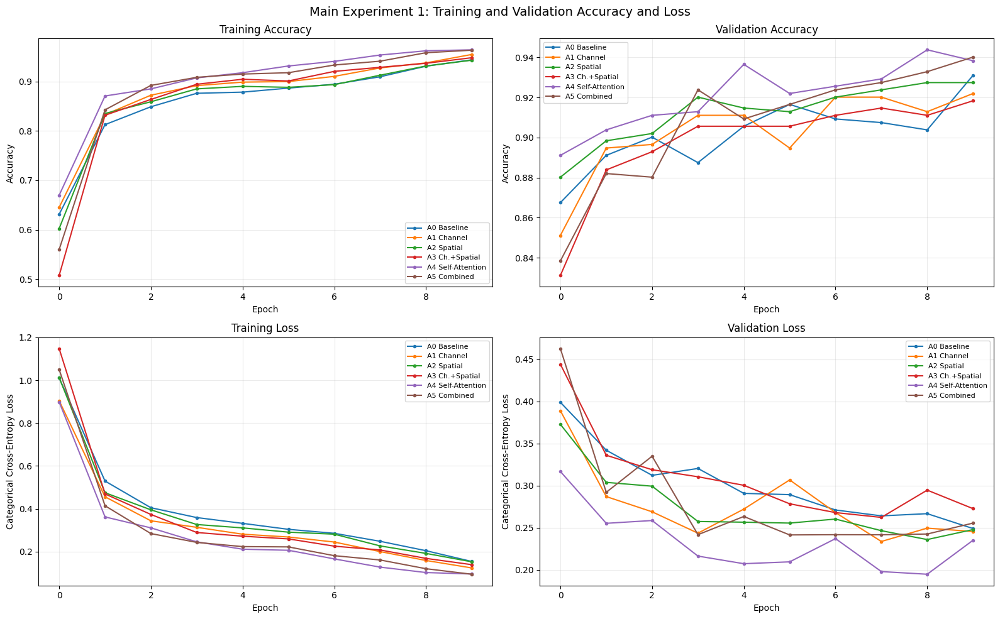

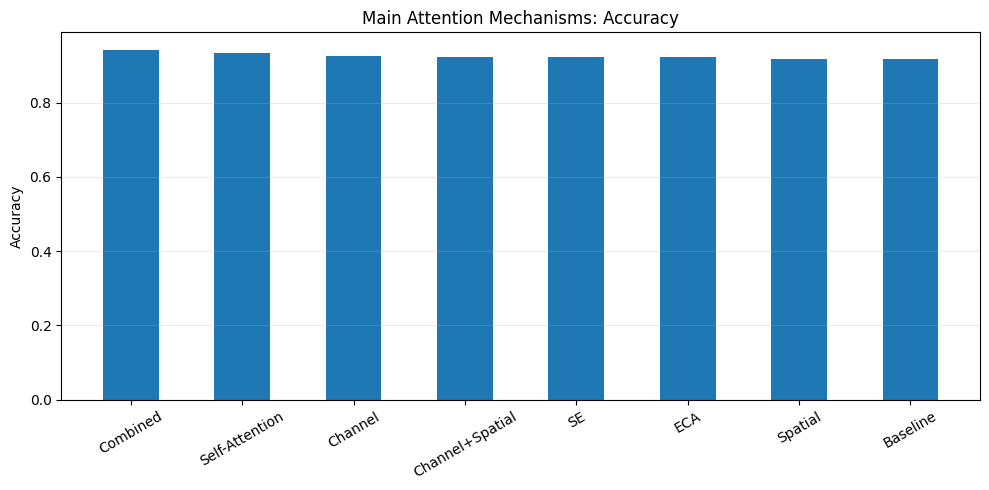

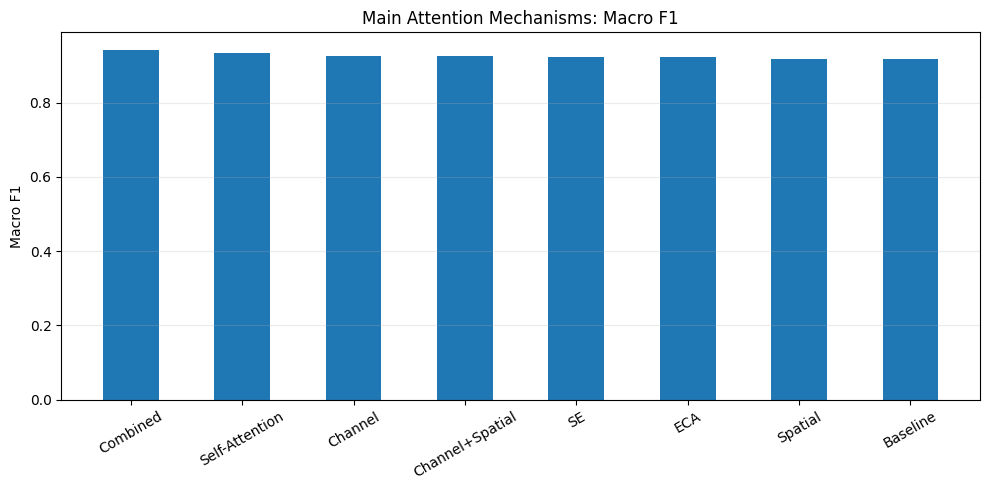

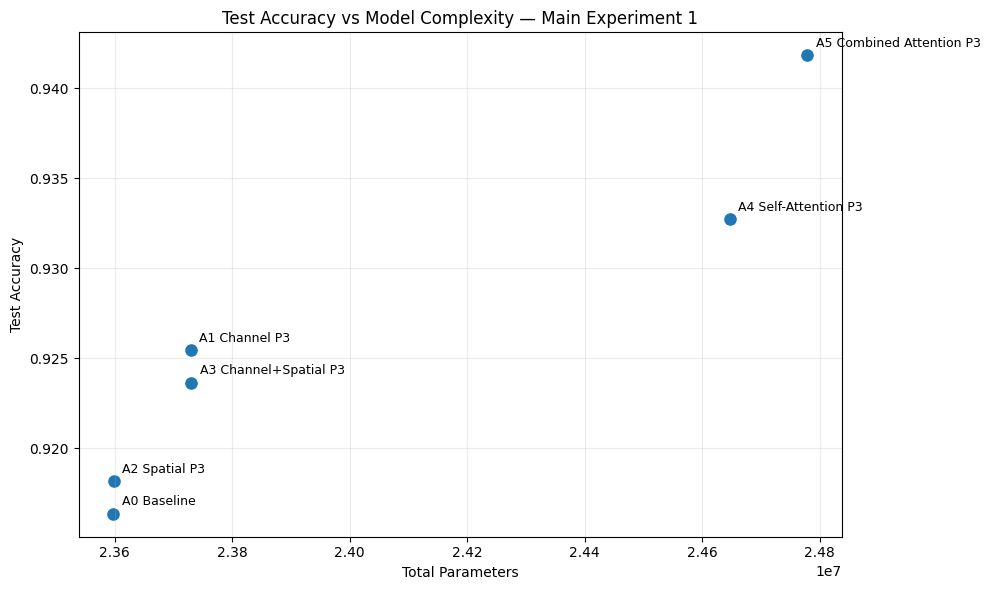

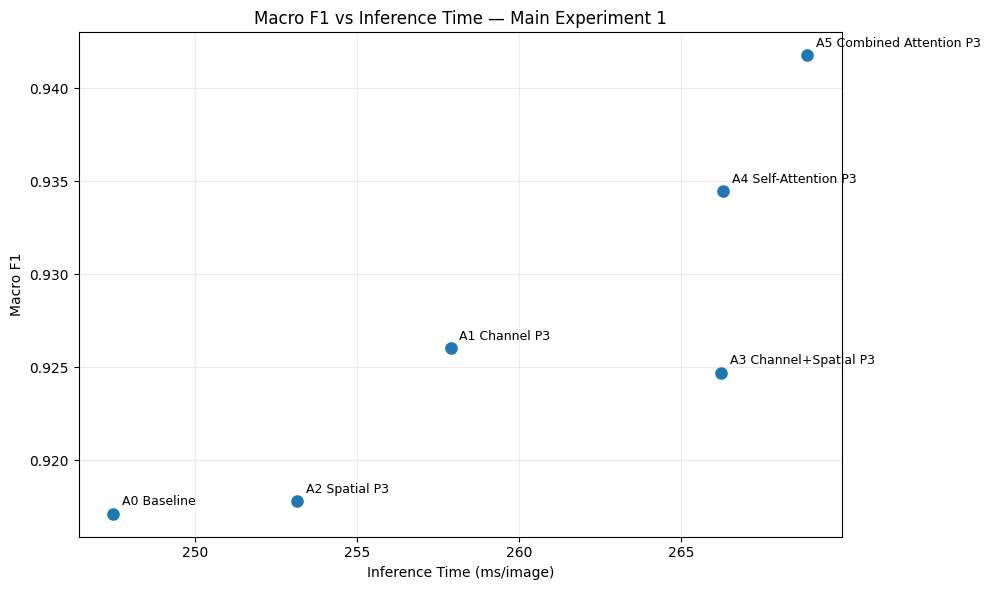

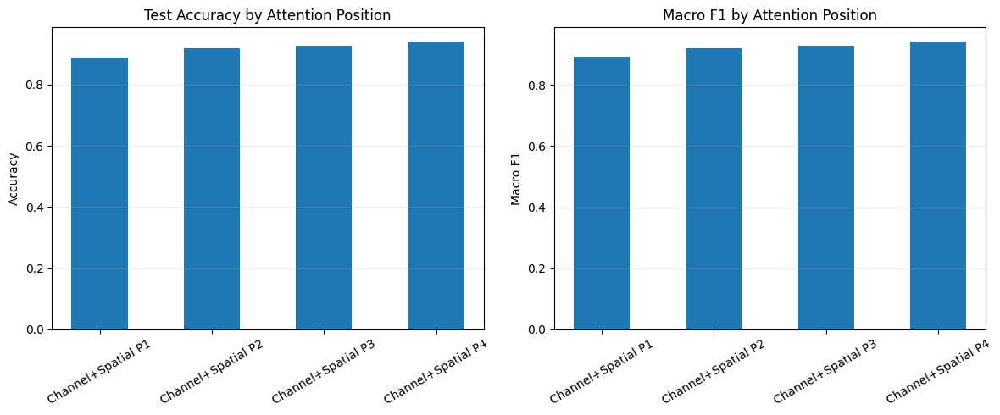

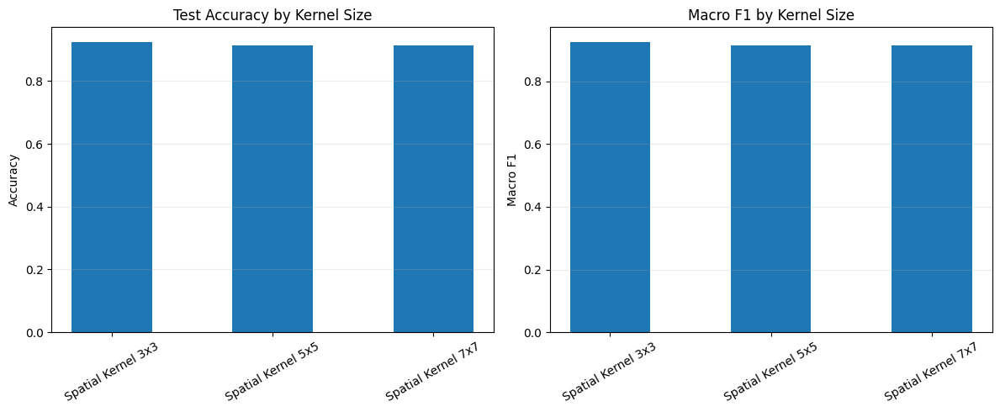

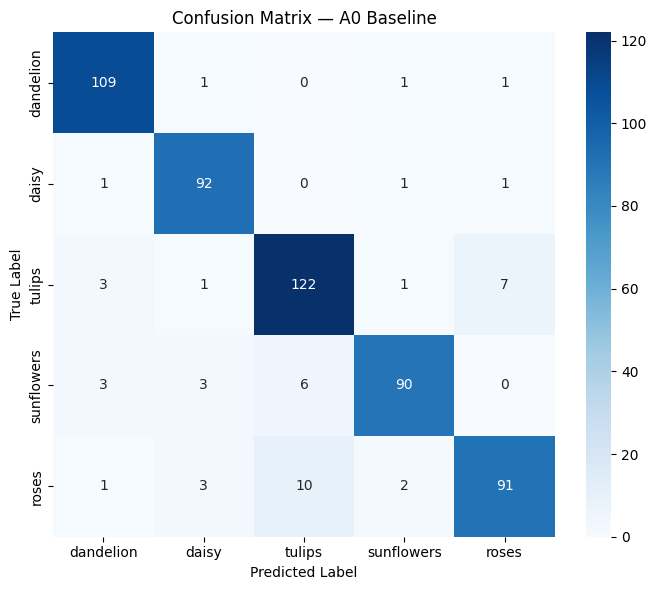


Classification Report — A0 Baseline
              precision    recall  f1-score   support

   dandelion       0.93      0.97      0.95       112
       daisy       0.92      0.97      0.94        95
      tulips       0.88      0.91      0.90       134
  sunflowers       0.95      0.88      0.91       102
       roses       0.91      0.85      0.88       107

    accuracy                           0.92       550
   macro avg       0.92      0.92      0.92       550
weighted avg       0.92      0.92      0.92       550



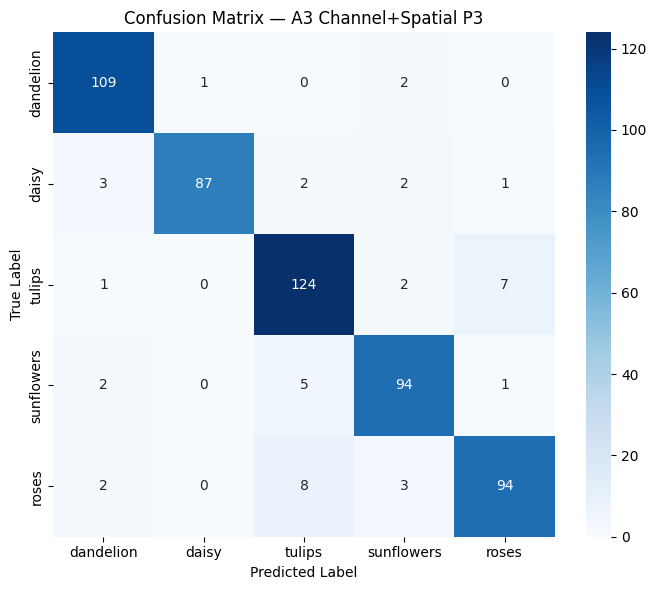


Classification Report — A3 Channel+Spatial P3
              precision    recall  f1-score   support

   dandelion       0.93      0.97      0.95       112
       daisy       0.99      0.92      0.95        95
      tulips       0.89      0.93      0.91       134
  sunflowers       0.91      0.92      0.92       102
       roses       0.91      0.88      0.90       107

    accuracy                           0.92       550
   macro avg       0.93      0.92      0.92       550
weighted avg       0.92      0.92      0.92       550



In [17]:

# ============================================================
# EVALUATION, RESULTS TABLES AND VISUALIZATIONS
# Reuses trained models; does not train any models.
# ============================================================

# 1. Collect all trained experiment runs.
all_runs = {}

for group in [
    experiment1,
    experiment2,
    experiment3,
    experiment4,
    experiment5,
    additional
]:
    all_runs.update(group)


# ============================================================
# 2. EVALUATE MODELS AND CREATE RESULTS TABLE
# ============================================================

result_rows = []

for name, run in all_runs.items():
    # Reuse evaluation results if already available.
    if "evaluation" not in run:
        print("Evaluating:", name)
        run["evaluation"] = evaluate_model(name, run["model"])

    row = run["evaluation"]

    result_rows.append({
        k: v
        for k, v in row.items()
        if k not in ("y_true", "y_pred")
    })


results_df = (
    pd.DataFrame(result_rows)
    .sort_values("Accuracy", ascending=False)
    .reset_index(drop=True)
)

display(results_df.round(4))

results_df.to_csv("attention_experiment_results.csv", index=False)
print("Results saved to attention_experiment_results.csv")


# ============================================================
# 3. MAIN EXPERIMENT 1: FOUR SEPARATE TRAINING CURVES
# ============================================================

selected_histories = {
    "A0 Baseline": experiment1["A0 Baseline"]["history"],
    "A1 Channel": experiment1["A1 Channel P3"]["history"],
    "A2 Spatial": experiment1["A2 Spatial P3"]["history"],
    "A3 Ch.+Spatial": experiment1["A3 Channel+Spatial P3"]["history"],
    "A4 Self-Attention": experiment1["A4 Self-Attention P3"]["history"],
    "A5 Combined": experiment1["A5 Combined Attention P3"]["history"],
}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Training accuracy
ax = axes[0, 0]
for name, hist in selected_histories.items():
    ax.plot(hist["accuracy"], marker="o", markersize=3, label=name)

ax.set_title("Training Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

# Validation accuracy
ax = axes[0, 1]
for name, hist in selected_histories.items():
    ax.plot(hist["val_accuracy"], marker="o", markersize=3, label=name)

ax.set_title("Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

# Training loss
ax = axes[1, 0]
for name, hist in selected_histories.items():
    ax.plot(hist["loss"], marker="o", markersize=3, label=name)

ax.set_title("Training Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Categorical Cross-Entropy Loss")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

# Validation loss
ax = axes[1, 1]
for name, hist in selected_histories.items():
    ax.plot(hist["val_loss"], marker="o", markersize=3, label=name)

ax.set_title("Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Categorical Cross-Entropy Loss")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

fig.suptitle(
    "Main Experiment 1: Training and Validation Accuracy and Loss",
    fontsize=14
)
plt.tight_layout()
plt.show()


# ============================================================
# 4. MAIN MECHANISM COMPARISON: ACCURACY AND MACRO F1
# ============================================================

mechanism_names = [
    "A0 Baseline",
    "A1 Channel P3",
    "A2 Spatial P3",
    "A3 Channel+Spatial P3",
    "A4 Self-Attention P3",
    "A5 Combined Attention P3",
    "Additional SE P3",
    "Additional ECA P3",
]

mechanism_df = results_df[
    results_df["Model"].isin(mechanism_names)
].copy()

short_labels = {
    "A0 Baseline": "Baseline",
    "A1 Channel P3": "Channel",
    "A2 Spatial P3": "Spatial",
    "A3 Channel+Spatial P3": "Channel+Spatial",
    "A4 Self-Attention P3": "Self-Attention",
    "A5 Combined Attention P3": "Combined",
    "Additional SE P3": "SE",
    "Additional ECA P3": "ECA",
}

mechanism_df["Short Name"] = mechanism_df["Model"].map(short_labels)
mechanism_df = mechanism_df.sort_values("Accuracy", ascending=False)

for metric in ["Accuracy", "Macro F1"]:
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.bar(
        mechanism_df["Short Name"],
        mechanism_df[metric],
        width=0.5
    )

    ax.set_ylabel(metric)
    ax.set_title(f"Main Attention Mechanisms: {metric}")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()


# ============================================================
# 5. ACCURACY VS MODEL COMPLEXITY
# MAIN EXPERIMENT 1: SIX MODELS ONLY
# ============================================================

main_model_names = [
    "A0 Baseline",
    "A1 Channel P3",
    "A2 Spatial P3",
    "A3 Channel+Spatial P3",
    "A4 Self-Attention P3",
    "A5 Combined Attention P3",
]

main_df = results_df[
    results_df["Model"].isin(main_model_names)
].copy()

main_df["Model"] = pd.Categorical(
    main_df["Model"],
    categories=main_model_names,
    ordered=True
)

main_df = main_df.sort_values("Model")

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    main_df["Total Parameters"],
    main_df["Accuracy"],
    s=65
)

for _, row in main_df.iterrows():
    ax.annotate(
        str(row["Model"]),
        (row["Total Parameters"], row["Accuracy"]),
        fontsize=9,
        xytext=(6, 6),
        textcoords="offset points"
    )

ax.set_xlabel("Total Parameters")
ax.set_ylabel("Test Accuracy")
ax.set_title("Test Accuracy vs Model Complexity — Main Experiment 1")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# 6. MACRO F1 VS INFERENCE TIME
# MAIN EXPERIMENT 1: SIX MODELS ONLY
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    main_df["Inference Time (ms/image)"],
    main_df["Macro F1"],
    s=65
)

for _, row in main_df.iterrows():
    ax.annotate(
        str(row["Model"]),
        (row["Inference Time (ms/image)"], row["Macro F1"]),
        fontsize=9,
        xytext=(6, 6),
        textcoords="offset points"
    )

ax.set_xlabel("Inference Time (ms/image)")
ax.set_ylabel("Macro F1")
ax.set_title("Macro F1 vs Inference Time — Main Experiment 1")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# 7. EXPERIMENT 2: ATTENTION POSITION
# ============================================================

position_names = list(experiment2.keys())

position_df = (
    results_df.set_index("Model")
    .loc[position_names]
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy by position
axes[0].bar(
    position_df["Model"],
    position_df["Accuracy"],
    width=0.5
)

axes[0].set_title("Test Accuracy by Attention Position")
axes[0].set_ylabel("Accuracy")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="y", alpha=0.25)

# Macro F1 by position
axes[1].bar(
    position_df["Model"],
    position_df["Macro F1"],
    width=0.5
)

axes[1].set_title("Macro F1 by Attention Position")
axes[1].set_ylabel("Macro F1")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# 8. EXPERIMENT 5: SPATIAL ATTENTION KERNEL SIZE
# ============================================================

kernel_names = list(experiment5.keys())

kernel_df = (
    results_df.set_index("Model")
    .loc[kernel_names]
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy by kernel size
axes[0].bar(
    kernel_df["Model"],
    kernel_df["Accuracy"],
    width=0.5
)

axes[0].set_title("Test Accuracy by Kernel Size")
axes[0].set_ylabel("Accuracy")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="y", alpha=0.25)

# Macro F1 by kernel size
axes[1].bar(
    kernel_df["Model"],
    kernel_df["Macro F1"],
    width=0.5
)

axes[1].set_title("Macro F1 by Kernel Size")
axes[1].set_ylabel("Macro F1")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# 9. CONFUSION MATRICES AND CLASSIFICATION REPORTS
# ============================================================

for name in [
    "A0 Baseline",
    "A3 Channel+Spatial P3"
]:
    row = all_runs[name]["evaluation"]

    cm = confusion_matrix(
        row["y_true"],
        row["y_pred"],
        labels=range(NUM_CLASSES)
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"Confusion Matrix — {name}")

    plt.tight_layout()
    plt.show()

    print(f"\nClassification Report — {name}")

    print(
        classification_report(
            row["y_true"],
            row["y_pred"],
            labels=range(NUM_CLASSES),
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )


## Qualitative analysis — feature maps, internal attention maps, and Grad-CAM

Representative image — true class: daisy


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['image']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


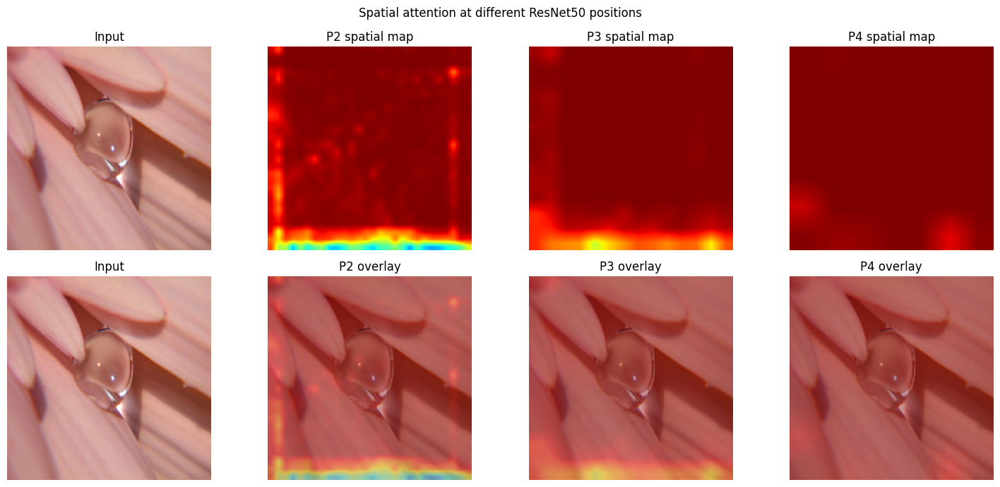

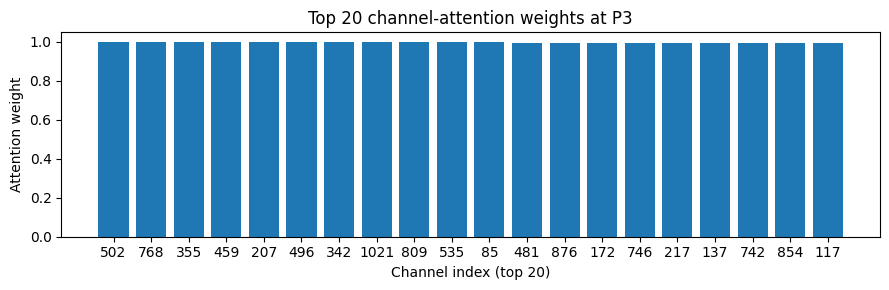

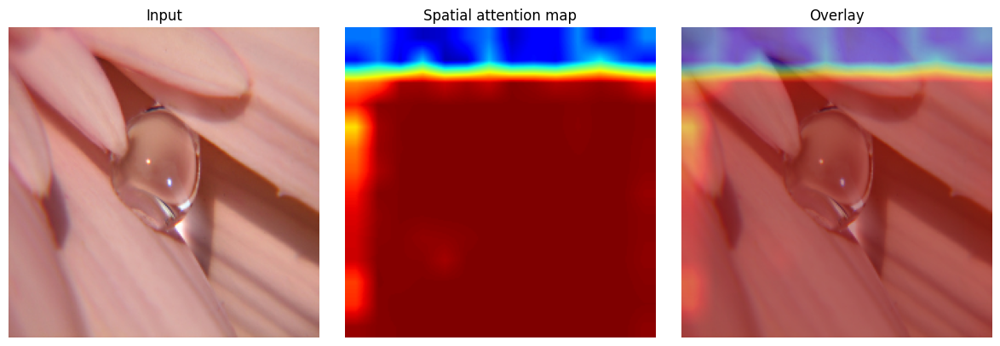

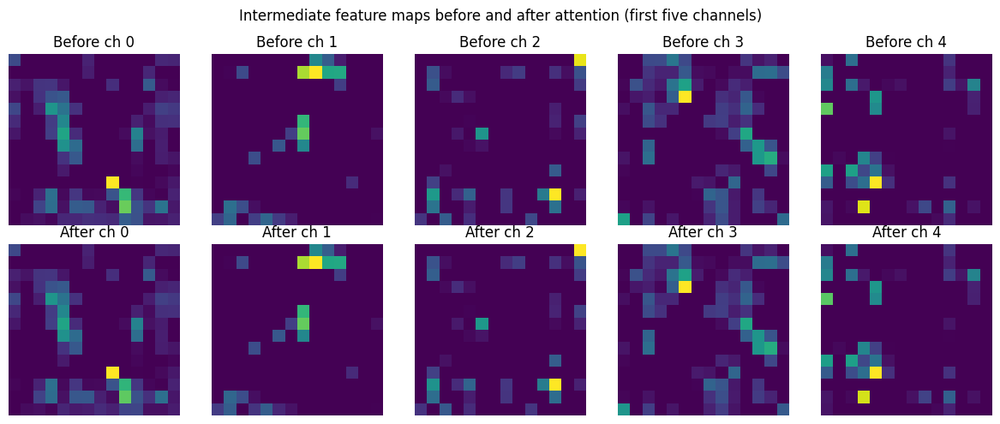

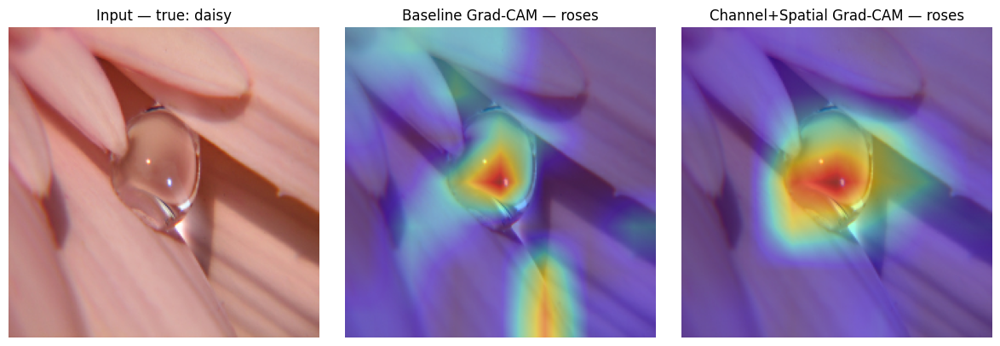

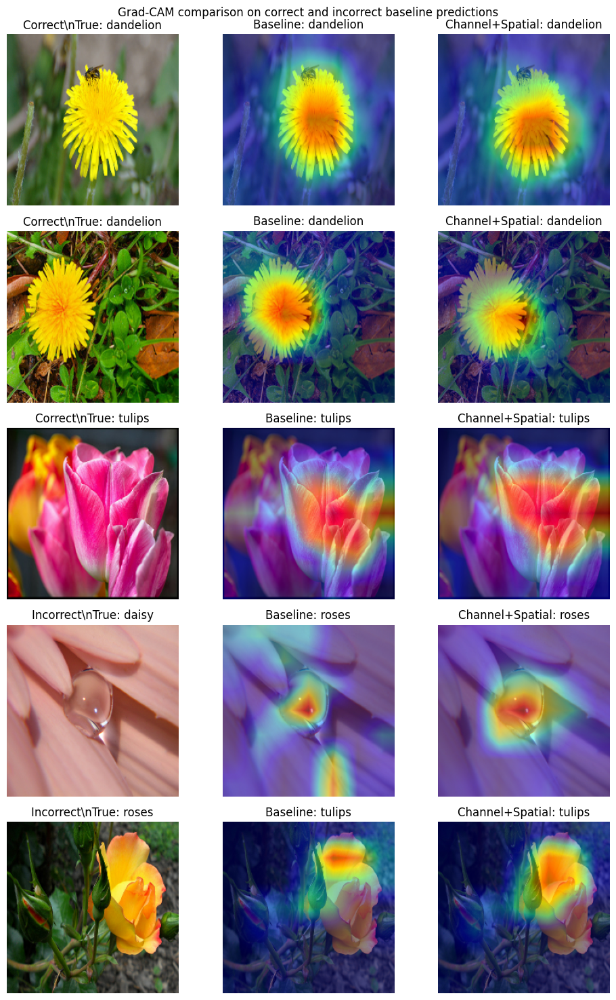

In [18]:
# Reuse one fixed test image for all map comparisons.
qual_image, qual_label = next(iter(test_ds))
image = qual_image[0].numpy()
true_class = int(np.argmax(qual_label[0].numpy()))
display_image = np.clip(image / 255.0, 0, 1)
print("Representative image — true class:", CLASS_NAMES[true_class])

def get_layer_map(model, layer_name, image_batch):
    layer = model.get_layer(layer_name)
    probe = tf.keras.Model(model.inputs, layer.output)
    return probe(image_batch, training=False).numpy()

def resize_map(map2d, size=(IMG_SIZE, IMG_SIZE)):
    map2d = tf.convert_to_tensor(map2d, dtype=tf.float32)
    if map2d.shape.rank == 2: map2d = map2d[..., None]
    return tf.image.resize(map2d[None, ...], size, method="bilinear")[0, ..., 0].numpy()

# Internal spatial attention map and overlay at P2/P3/P4.
position_runs = {"P2": experiment2["Channel+Spatial P2"],
                 "P3": experiment2["Channel+Spatial P3"],
                 "P4": experiment2["Channel+Spatial P4"]}
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes[0, 0].imshow(display_image); axes[0, 0].set_title("Input")
axes[1, 0].imshow(display_image); axes[1, 0].set_title("Input")
for col, pos in enumerate(["P2", "P3", "P4"], start=1):
    run = position_runs[pos]
    model = run["model"]
    layer_name = f"spatial_{pos.lower()}_weights"
    try:
        weights = get_layer_map(model, layer_name, image[None, ...])[0, ..., 0]
        up = resize_map(weights)
        axes[0, col].imshow(up, cmap="jet", vmin=0, vmax=1)
        axes[0, col].set_title(f"{pos} spatial map")
        axes[1, col].imshow(display_image); axes[1, col].imshow(up, cmap="jet", alpha=.42, vmin=0, vmax=1)
        axes[1, col].set_title(f"{pos} overlay")
    except Exception as exc:
        axes[0, col].text(.1, .5, f"Map unavailable\\n{exc}", wrap=True)
        axes[1, col].axis("off")
for ax in axes.flat: ax.axis("off")
plt.suptitle("Spatial attention at different ResNet50 positions")
plt.tight_layout(); plt.show()

# Channel-attention weights (top 20) and feature maps before/after attention.
channel_run = experiment1["A1 Channel P3"]
channel_model = channel_run["model"]
try:
    channel_weights = get_layer_map(channel_model, "channel_p3_weights", image[None, ...])[0, 0, 0]
    top_idx = np.argsort(channel_weights)[-20:][::-1]
    plt.figure(figsize=(9, 3))
    plt.bar([str(i) for i in top_idx], channel_weights[top_idx])
    plt.xlabel("Channel index (top 20)"); plt.ylabel("Attention weight")
    plt.title("Top 20 channel-attention weights at P3"); plt.tight_layout(); plt.show()
except Exception as exc:
    print("Channel-weight visualization could not be extracted:", exc)

spatial_model = experiment1["A2 Spatial P3"]["model"]
try:
    spatial_weights = get_layer_map(spatial_model, "spatial_p3_weights", image[None, ...])[0, ..., 0]
    up = resize_map(spatial_weights)
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(display_image); axes[0].set_title("Input")
    axes[1].imshow(up, cmap="jet", vmin=0, vmax=1); axes[1].set_title("Spatial attention map")
    axes[2].imshow(display_image); axes[2].imshow(up, cmap="jet", alpha=.45, vmin=0, vmax=1); axes[2].set_title("Overlay")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()
except Exception as exc:
    print("Spatial-attention visualization could not be extracted:", exc)

# Feature map before/after the P3 channel+spatial block.
try:
    cs_model = experiment1["A3 Channel+Spatial P3"]["model"]
    before = get_layer_map(cs_model, "features_p3", image[None, ...])[0]
    after = get_layer_map(cs_model, "spatial_p3_refined", image[None, ...])[0]
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for i in range(5):
        axes[0, i].imshow(before[:, :, i], cmap="viridis"); axes[0, i].set_title(f"Before ch {i}")
        axes[1, i].imshow(after[:, :, i], cmap="viridis"); axes[1, i].set_title(f"After ch {i}")
    for ax in axes.flat: ax.axis("off")
    plt.suptitle("Intermediate feature maps before and after attention (first five channels)")
    plt.tight_layout(); plt.show()
except Exception as exc:
    print("Feature-map visualization could not be extracted:", exc)

# Grad-CAM using gradients with respect to the last convolutional feature tensor.
def gradcam(run, image_array, class_index=None):
    feature_model = run["feature_model"]
    x = tf.convert_to_tensor(image_array[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        probs, features = feature_model(x, training=False)
        if class_index is None: class_index = int(tf.argmax(probs[0]).numpy())
        score = probs[:, class_index]
    grads = tape.gradient(score, features)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * features, axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + tf.keras.backend.epsilon())
    return resize_map(cam), int(tf.argmax(probs[0]).numpy())

baseline_run = experiment1["A0 Baseline"]
attention_run = experiment1["A3 Channel+Spatial P3"]
cam_base, pred_base = gradcam(baseline_run, image)
cam_att, pred_att = gradcam(attention_run, image)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(display_image); axes[0].set_title(f"Input — true: {CLASS_NAMES[true_class]}")
axes[1].imshow(display_image); axes[1].imshow(cam_base, cmap="jet", alpha=.45); axes[1].set_title(f"Baseline Grad-CAM — {CLASS_NAMES[pred_base]}")
axes[2].imshow(display_image); axes[2].imshow(cam_att, cmap="jet", alpha=.45); axes[2].set_title(f"Channel+Spatial Grad-CAM — {CLASS_NAMES[pred_att]}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()



# At least three correct and two incorrect predictions, when available.
y_true = all_runs["A0 Baseline"]["evaluation"]["y_true"]
y_pred = all_runs["A0 Baseline"]["evaluation"]["y_pred"]
correct_idx = np.where(y_true == y_pred)[0][:3]
wrong_idx = np.where(y_true != y_pred)[0][:2]
chosen = list(correct_idx) + list(wrong_idx)
if chosen:
    test_images, test_labels = [], []
    for imgs, labels in test_ds:
        test_images.extend(imgs.numpy())
        test_labels.extend(np.argmax(labels.numpy(), axis=1))
    fig, axes = plt.subplots(len(chosen), 3, figsize=(10, 3 * len(chosen)))
    if len(chosen) == 1: axes = np.expand_dims(axes, 0)
    for row, idx in enumerate(chosen):
        img = test_images[idx]
        base_cam, base_pred = gradcam(baseline_run, img)
        att_cam, att_pred = gradcam(attention_run, img)
        axes[row, 0].imshow(np.clip(img / 255.0, 0, 1))
        axes[row, 0].set_title(f"{'Correct' if y_true[idx] == y_pred[idx] else 'Incorrect'}\\nTrue: {CLASS_NAMES[y_true[idx]]}")
        axes[row, 1].imshow(np.clip(img / 255.0, 0, 1)); axes[row, 1].imshow(base_cam, cmap="jet", alpha=.45)
        axes[row, 1].set_title(f"Baseline: {CLASS_NAMES[base_pred]}")
        axes[row, 2].imshow(np.clip(img / 255.0, 0, 1)); axes[row, 2].imshow(att_cam, cmap="jet", alpha=.45)
        axes[row, 2].set_title(f"Channel+Spatial: {CLASS_NAMES[att_pred]}")
    for ax in axes.flat: ax.axis("off")
    plt.suptitle("Grad-CAM comparison on correct and incorrect baseline predictions")
    plt.tight_layout(); plt.show()
else:
    print("No test examples available for qualitative comparison.")

In [ ]:

# Feature maps before/after attention + input + spatial attention overlay
# Reuses the existing trained A3 Channel+Spatial P3 model.

cs_model = experiment1["A3 Channel+Spatial P3"]["model"]

# Extract actual intermediate activations.
before = get_layer_map(
    cs_model, "features_p3", image[None, ...]
)[0]

after = get_layer_map(
    cs_model, "spatial_p3_refined", image[None, ...]
)[0]

# Extract the spatial attention weights from the same model.
spatial_weights = get_layer_map(
    cs_model, "spatial_p3_weights", image[None, ...]
)[0, ..., 0]

spatial_map = resize_map(spatial_weights)
shown = np.clip(image / 255.0, 0, 1)

# Mean activation across all channels.
mean_before = np.mean(before, axis=-1)
mean_after = np.mean(after, axis=-1)

# Shared colour scale for comparing mean activation maps.
vmin = min(mean_before.min(), mean_after.min())
vmax = max(mean_before.max(), mean_after.max())

fig, axes = plt.subplots(3, 6, figsize=(19, 10))

# Row 1: input, spatial attention, overlay, and individual channels before.
axes[0, 0].imshow(shown)
axes[0, 0].set_title("Input image")

axes[0, 1].imshow(spatial_map, cmap="jet", vmin=0, vmax=1)
axes[0, 1].set_title("Spatial attention map")

axes[0, 2].imshow(shown)
axes[0, 2].imshow(
    spatial_map, cmap="jet", alpha=0.45, vmin=0, vmax=1
)
axes[0, 2].set_title("Spatial attention overlay")

for i in range(3):
    axes[0, i + 3].imshow(before[:, :, i], cmap="viridis")
    axes[0, i + 3].set_title(f"Before attention — ch {i}")

# Row 2: five individual feature channels after attention.
for i in range(5):
    axes[1, i].imshow(after[:, :, i], cmap="viridis")
    axes[1, i].set_title(f"After attention — ch {i}")

# Include the input again for convenient visual reference.
axes[1, 5].imshow(shown)
axes[1, 5].set_title("Input reference")

# Row 3: mean activation before, after, and difference.
axes[2, 0].imshow(
    mean_before, cmap="viridis", vmin=vmin, vmax=vmax
)
axes[2, 0].set_title("Mean activation before")

axes[2, 1].imshow(
    mean_after, cmap="viridis", vmin=vmin, vmax=vmax
)
axes[2, 1].set_title("Mean activation after")

axes[2, 2].imshow(mean_after - mean_before, cmap="coolwarm")
axes[2, 2].set_title("Mean activation change")

# Leave remaining panels empty to keep the layout aligned.
for j in range(3, 6):
    axes[2, j].axis("off")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    "Input, Spatial Attention and Feature Maps Before/After Attention",
    fontsize=14
)
plt.tight_layout()
plt.show()

print("Feature tensor before attention:", before.shape)
print("Feature tensor after attention:", after.shape)
print("Spatial attention map:", spatial_map.shape)


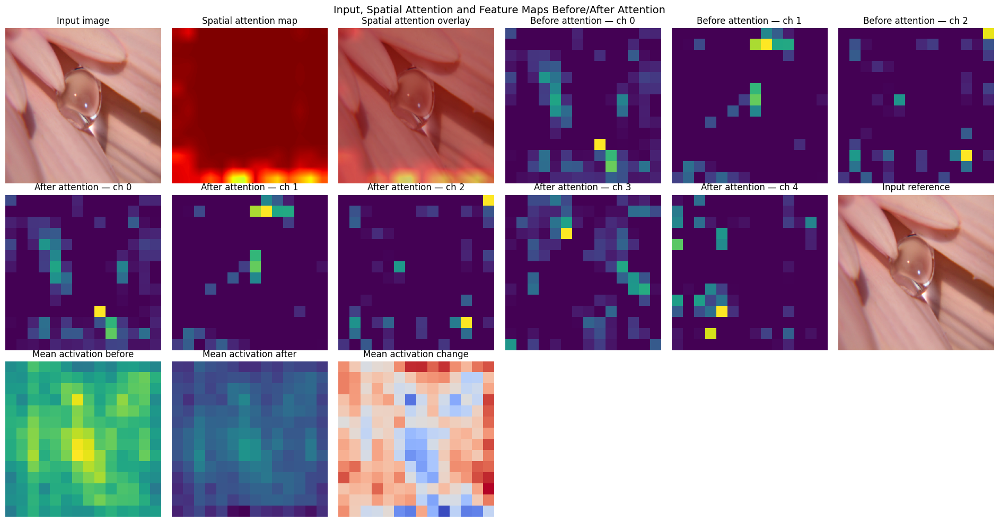

Feature tensor before attention: (14, 14, 1024)
Feature tensor after attention: (14, 14, 1024)
Spatial attention map: (224, 224)


In [24]:

# Feature maps before/after attention + input + spatial attention overlay
# Reuses the existing trained A3 Channel+Spatial P3 model.

cs_model = experiment1["A3 Channel+Spatial P3"]["model"]

# Extract actual intermediate activations.
before = get_layer_map(
    cs_model, "features_p3", image[None, ...]
)[0]

after = get_layer_map(
    cs_model, "spatial_p3_refined", image[None, ...]
)[0]

# Extract the spatial attention weights from the same model.
spatial_weights = get_layer_map(
    cs_model, "spatial_p3_weights", image[None, ...]
)[0, ..., 0]

spatial_map = resize_map(spatial_weights)
shown = np.clip(image / 255.0, 0, 1)

# Mean activation across all channels.
mean_before = np.mean(before, axis=-1)
mean_after = np.mean(after, axis=-1)

# Shared colour scale for comparing mean activation maps.
vmin = min(mean_before.min(), mean_after.min())
vmax = max(mean_before.max(), mean_after.max())

fig, axes = plt.subplots(3, 6, figsize=(19, 10))

# Row 1: input, spatial attention, overlay, and individual channels before.
axes[0, 0].imshow(shown)
axes[0, 0].set_title("Input image")

axes[0, 1].imshow(spatial_map, cmap="jet", vmin=0, vmax=1)
axes[0, 1].set_title("Spatial attention map")

axes[0, 2].imshow(shown)
axes[0, 2].imshow(
    spatial_map, cmap="jet", alpha=0.45, vmin=0, vmax=1
)
axes[0, 2].set_title("Spatial attention overlay")

for i in range(3):
    axes[0, i + 3].imshow(before[:, :, i], cmap="viridis")
    axes[0, i + 3].set_title(f"Before attention — ch {i}")

# Row 2: five individual feature channels after attention.
for i in range(5):
    axes[1, i].imshow(after[:, :, i], cmap="viridis")
    axes[1, i].set_title(f"After attention — ch {i}")

# Include the input again for convenient visual reference.
axes[1, 5].imshow(shown)
axes[1, 5].set_title("Input reference")

# Row 3: mean activation before, after, and difference.
axes[2, 0].imshow(
    mean_before, cmap="viridis", vmin=vmin, vmax=vmax
)
axes[2, 0].set_title("Mean activation before")

axes[2, 1].imshow(
    mean_after, cmap="viridis", vmin=vmin, vmax=vmax
)
axes[2, 1].set_title("Mean activation after")

axes[2, 2].imshow(mean_after - mean_before, cmap="coolwarm")
axes[2, 2].set_title("Mean activation change")

# Leave remaining panels empty to keep the layout aligned.
for j in range(3, 6):
    axes[2, j].axis("off")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    "Input, Spatial Attention and Feature Maps Before/After Attention",
    fontsize=14
)
plt.tight_layout()
plt.show()

print("Feature tensor before attention:", before.shape)
print("Feature tensor after attention:", after.shape)
print("Spatial attention map:", spatial_map.shape)


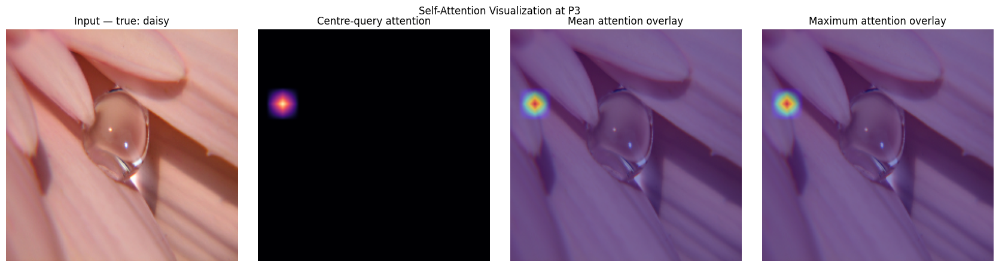

In [20]:
# Actual self-attention visualization — reuse the trained A4 model
self_run = experiment1["A4 Self-Attention P3"]
self_model = self_run["model"]
self_layer = self_model.get_layer("self_P3")

# Run inference only; this does not train the model.
_ = self_model(image[None, ...], training=False)
attn = self_layer.last_attention

if attn is None:
    raise RuntimeError("Self-attention matrix was not captured.")

# 1. Mean attention across all query positions.
mean_response = tf.reduce_mean(attn, axis=1)[0]
mean_response = tf.reshape(
    mean_response, (self_layer.h, self_layer.w)
).numpy()

mean_response = mean_response / (mean_response.max() + 1e-8)
mean_response = resize_map(mean_response)

# 2. Attention distribution from the centre query location.
centre_idx = (
    (self_layer.h // 2) * self_layer.w
    + self_layer.w // 2
)

query_response = tf.reshape(
    attn[0, centre_idx],
    (self_layer.h, self_layer.w)
).numpy()

query_response = query_response / (query_response.max() + 1e-8)
query_response = resize_map(query_response)

# 3. Maximum attention received by each spatial location
# across all query positions.
max_response = tf.reduce_max(attn, axis=1)[0]
max_response = tf.reshape(
    max_response, (self_layer.h, self_layer.w)
).numpy()

max_response = max_response / (max_response.max() + 1e-8)
max_response = resize_map(max_response)

# Display all four visualizations.
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))

# Input image
axes[0].imshow(display_image)
axes[0].set_title(
    f"Input — true: {CLASS_NAMES[true_class]}"
)

# Centre-query attention map
axes[1].imshow(query_response, cmap="magma", vmin=0, vmax=1)
axes[1].set_title("Centre-query attention")

# Mean self-attention response with overlay
axes[2].imshow(display_image)
axes[2].imshow(
    mean_response,
    cmap="jet",
    alpha=0.45,
    vmin=0,
    vmax=1
)
axes[2].set_title("Mean attention overlay")

# Maximum self-attention response with overlay
axes[3].imshow(display_image)
axes[3].imshow(
    max_response,
    cmap="jet",
    alpha=0.45,
    vmin=0,
    vmax=1
)
axes[3].set_title("Maximum attention overlay")

for ax in axes:
    ax.axis("off")

plt.suptitle("Self-Attention Visualization at P3")
plt.tight_layout()
plt.show()

Correct examples: 3
Incorrect examples: 2


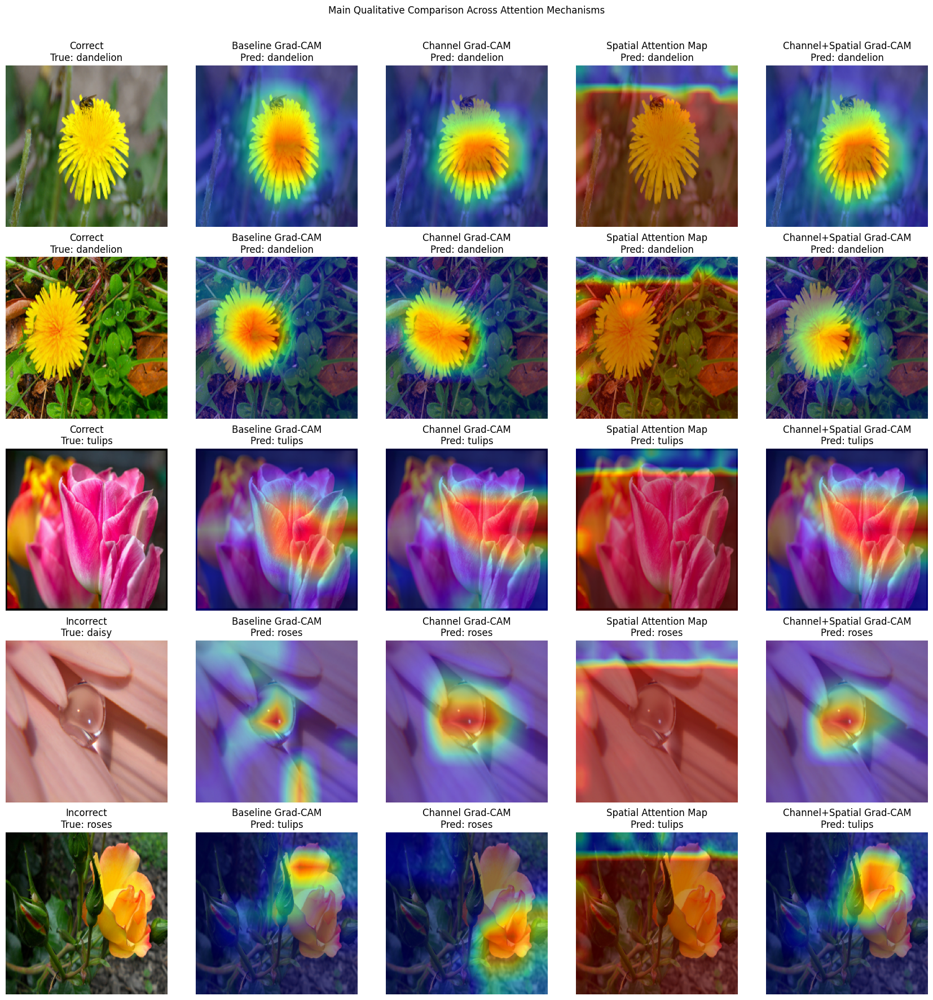

In [21]:

# Main qualitative comparison across attention mechanisms
# Uses existing trained models only — no retraining.

baseline_run = experiment1["A0 Baseline"]
channel_run = experiment1["A1 Channel P3"]
spatial_run = experiment1["A2 Spatial P3"]
cs_run = experiment1["A3 Channel+Spatial P3"]

# Select the same examples using baseline predictions.
y_true = all_runs["A0 Baseline"]["evaluation"]["y_true"]
y_pred = all_runs["A0 Baseline"]["evaluation"]["y_pred"]

test_images = []
for imgs, labels in test_ds:
    test_images.extend(imgs.numpy())
test_images = np.asarray(test_images)

correct_idx = np.where(y_true == y_pred)[0][:3]
wrong_idx = np.where(y_true != y_pred)[0][:2]
chosen = list(correct_idx) + list(wrong_idx)

print(f"Correct examples: {len(correct_idx)}")
print(f"Incorrect examples: {len(wrong_idx)}")

if len(correct_idx) < 3 or len(wrong_idx) < 2:
    print("Warning: fewer than the requested 3 correct or 2 incorrect "
          "baseline examples are available.")

fig, axes = plt.subplots(
    len(chosen), 5,
    figsize=(17, 3.5 * len(chosen)),
    squeeze=False
)

for row, idx in enumerate(chosen):
    img = test_images[idx]
    shown = np.clip(img / 255.0, 0, 1)
    true_name = CLASS_NAMES[int(y_true[idx])]
    status = "Correct" if y_true[idx] == y_pred[idx] else "Incorrect"

    # 1. Input image
    axes[row, 0].imshow(shown)
    axes[row, 0].set_title(f"{status}\nTrue: {true_name}")

    # 2–3. Baseline and channel-attention Grad-CAM
    for col, run, title in [
        (1, baseline_run, "Baseline Grad-CAM"),
        (2, channel_run, "Channel Grad-CAM"),
        (4, cs_run, "Channel+Spatial Grad-CAM")
    ]:
        cam, pred = gradcam(run, img)
        axes[row, col].imshow(shown)
        axes[row, col].imshow(
            cam, cmap="jet", alpha=0.45, vmin=0, vmax=1
        )
        axes[row, col].set_title(
            f"{title}\nPred: {CLASS_NAMES[pred]}"
        )

    # 4. Actual spatial-attention map overlaid on the input
    spatial_weights = get_layer_map(
        spatial_run["model"],
        "spatial_p3_weights",
        img[None, ...]
    )[0, ..., 0]
    spatial_map = resize_map(spatial_weights)

    axes[row, 3].imshow(shown)
    axes[row, 3].imshow(
        spatial_map, cmap="jet", alpha=0.45, vmin=0, vmax=1
    )
    _, spatial_pred = gradcam(spatial_run, img)
    axes[row, 3].set_title(
        f"Spatial Attention Map\nPred: {CLASS_NAMES[spatial_pred]}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    "Main Qualitative Comparison Across Attention Mechanisms",
    y=1.01
)
plt.tight_layout()
plt.show()


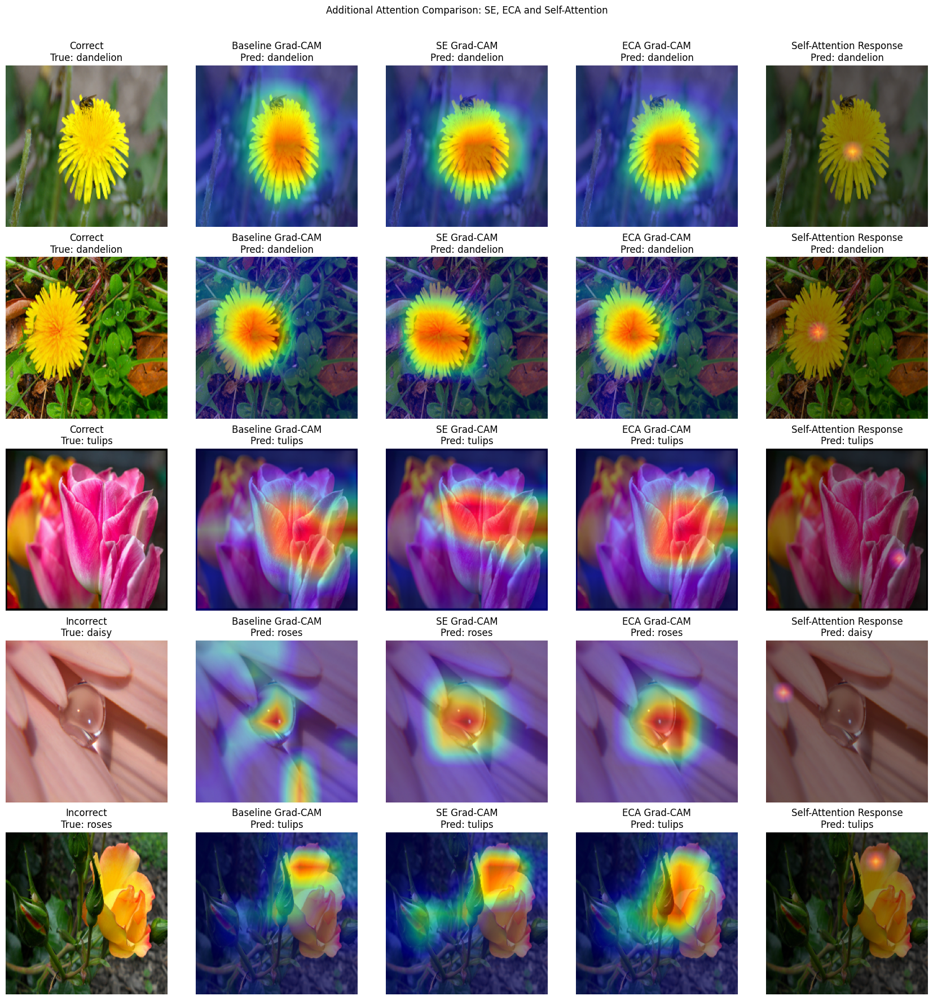

In [23]:

# Additional qualitative comparison: SE, ECA and self-attention
# Reuses the same test images selected in Cell 1 and existing trained models.

baseline_run = experiment1["A0 Baseline"]
self_run = experiment1["A4 Self-Attention P3"]
se_run = additional["Additional SE P3"]
eca_run = additional["Additional ECA P3"]

def get_self_attention_map(run, img):
    model = run["model"]

    # Use the actual layer name from the existing model.
    layer_names = [layer.name for layer in model.layers]
    self_layer_name = next(
        (name for name in ["self_p3", "self_P3"] if name in layer_names),
        None
    )
    if self_layer_name is None:
        raise ValueError(
            f"Self-attention layer not found. Available layers: {layer_names}"
        )

    layer = model.get_layer(self_layer_name)
    _ = model(img[None, ...], training=False)
    attention = layer.last_attention

    if attention is None:
        raise RuntimeError("Self-attention matrix was not captured.")

    # Aggregate attention received at each spatial location.
    response = tf.reduce_mean(attention, axis=1)[0]
    response = tf.reshape(response, (layer.h, layer.w)).numpy()
    response = response / (response.max() + 1e-8)

    return resize_map(response)

fig, axes = plt.subplots(
    len(chosen), 5,
    figsize=(17, 3.5 * len(chosen)),
    squeeze=False
)

for row, idx in enumerate(chosen):
    img = test_images[idx]
    shown = np.clip(img / 255.0, 0, 1)
    true_name = CLASS_NAMES[int(y_true[idx])]
    status = "Correct" if y_true[idx] == y_pred[idx] else "Incorrect"

    # 1. Input image
    axes[row, 0].imshow(shown)
    axes[row, 0].set_title(f"{status}\nTrue: {true_name}")

    # 2–4. Baseline, SE and ECA Grad-CAM
    for col, run, title in [
        (1, baseline_run, "Baseline Grad-CAM"),
        (2, se_run, "SE Grad-CAM"),
        (3, eca_run, "ECA Grad-CAM")
    ]:
        cam, pred = gradcam(run, img)
        axes[row, col].imshow(shown)
        axes[row, col].imshow(
            cam, cmap="jet", alpha=0.45, vmin=0, vmax=1
        )
        axes[row, col].set_title(
            f"{title}\nPred: {CLASS_NAMES[pred]}"
        )

    # 5. Actual self-attention response
    attention_map = get_self_attention_map(self_run, img)
    axes[row, 4].imshow(shown)
    axes[row, 4].imshow(
        attention_map, cmap="magma", alpha=0.45, vmin=0, vmax=1
    )
    _, self_pred = gradcam(self_run, img)
    axes[row, 4].set_title(
        f"Self-Attention Response\nPred: {CLASS_NAMES[self_pred]}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    "Additional Attention Comparison: SE, ECA and Self-Attention",
    y=1.01
)
plt.tight_layout()
plt.show()


## Notes for interpretation

- Compare the **measured** test metrics and training curves; do not copy example scores from the assignment PDF.
- Internal attention maps are weights generated by an attention block; Grad-CAM is a gradient-based, post-hoc explanation. They are not interchangeable.
- Inference time depends on the runtime/hardware and is measured in this notebook; compare models on the same machine/session.
- The notebook trains many controlled variants and can take substantial time, especially on CPU. Run cells in order and keep the same runtime for fair comparisons.